In [5]:
import numpy as np
from matplotlib import pyplot as plt
from IPython import display

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

import psutil, traceback, gc, atexit

import cv2
import tempfile, os, re

import requests
import json
import time
import random
import unicodedata
import pandas as pd
import base64
import mimetypes


In [6]:
#functions from the feature extraction pipeline
def normalize_text(text):
    # Normalize unicode characters, remove markdown formatting, lowercase, and strip dashes
    if not text:
        return text
    
    text = str(text)
    text = text.replace('*', '').replace('<<', '').replace('>>', '')
    text = re.sub(r'[-\u2010-\u2015\u2212\uFE58\uFE63\uFF0D]', '', text)
    normalized = unicodedata.normalize('NFKD', text)
    ascii_text = normalized.encode('ASCII', 'ignore').decode('ASCII')

    # Clean up whitespace + lowercase
    return ' '.join(ascii_text.split()).lower()

def send_prompt(
    system=None,
    prompt=None,
    image_url=None,             # if set, we download to a temp file and inline it
    image_path=None,            # local file path (sent as data URL)
    image_detail="auto",        
    seed=None,
    azure_api_key=os.getenv("AZURE_API_KEY"),
    azure_chat_url=None,        # built if not provided
    azure_model_name=os.getenv("AZURE_MODEL_NAME"),
    max_completion_tokens=1024,
    temperature=float(os.getenv("TEMPERATURE", "1.0")),
    top_p=float(os.getenv("TOP_P", "1.0")),
    frequency_penalty=float(os.getenv("FREQUENCY_PENALTY", "0.0")),
    presence_penalty=float(os.getenv("PRESENCE_PENALTY", "0.0")),
    max_time=int(os.getenv("MAX_TIME", "30"))
):

    # --- default azure_chat_url if not supplied ---
    if azure_chat_url is None:
        azure_endpoint_base = "https://aipolling.services.ai.azure.com/models"
        azure_api_version  = "2024-05-01-preview"
        azure_chat_url = f"{azure_endpoint_base}/chat/completions?api-version={azure_api_version}"

    # --- helpers ---
    def guess_mime_from_ext(path):
        """Guess MIME type from file extension, fallback to image/jpeg."""
        mime, _ = mimetypes.guess_type(path)
        return mime if mime else "image/jpeg"

    def image_to_data_url(path, mime=None):
        """Read file, encode as base64, return as data URL."""
        if not os.path.exists(path):
            raise FileNotFoundError(f"image_path not found: {path}")
        if mime is None:
            mime = guess_mime_from_ext(path)
        with open(path, "rb") as f:
            encoded = base64.b64encode(f.read()).decode("utf-8")
        return f"data:{mime};base64,{encoded}"

    tmp_path = None
    # If image_url is provided, download it
    if image_url:
        ext = os.path.splitext(image_url)[1].lower()
        suffix = ext if ext else ".bin"
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=suffix)
        os.close(tmp_fd)  # we'll reopen with write
        resp_img = requests.get(image_url, timeout=max_time)
        if resp_img.status_code >= 400:
            raise RuntimeError(f"Failed to download image_url (HTTP {resp_img.status_code}): {image_url}")
        with open(tmp_path, "wb") as f:
            f.write(resp_img.content)
        image_path = tmp_path

    # --- build messages ---
    messages_list = []
    if system:
        messages_list.append({"role": "system", "content": system})

    user_content = [{"type": "text", "text": prompt}]

    if image_path:
        mime = guess_mime_from_ext(image_path)
        data_url = image_to_data_url(image_path, mime)
        user_content.append({
            "type": "image_url",
            "image_url": {"url": data_url, "detail": image_detail}
        })

    messages_list.append({"role": "user", "content": user_content})

    # --- body payload ---
    body = {
        "model": azure_model_name,
        "messages": messages_list,
        "temperature": float(temperature),
        "top_p": float(top_p),
        "frequency_penalty": float(frequency_penalty),
        "presence_penalty": float(presence_penalty),
        "max_completion_tokens": int(max_completion_tokens),
        "max_tokens": int(max_completion_tokens),  # compat
        "seed": int(seed) if seed is not None else None
    }

    # --- request ---
    headers = {
        "Content-Type": "application/json",
        "Accept": "application/json",
        "api-key": azure_api_key
    }

    resp = requests.post(
        azure_chat_url,
        headers=headers,
        json=body,
        timeout=max_time
    )

    raw_content = resp.text
    if resp.status_code != 200:
        raise RuntimeError(f"API request failed with status {resp.status_code}, body: {raw_content}")

    result = resp.json()

    # --- cleanup tmp file if used ---
    if tmp_path and os.path.exists(tmp_path):
        try:
            os.remove(tmp_path)
        except Exception:
            pass

    return result

# ------------------------------------------------------------
# 2. Load demographic categories from JSON
# ------------------------------------------------------------
with open("../generated_data/image_belief_features.json", "r", encoding="utf-8") as f:
    feature_data = json.load(f)

demo_features = feature_data["demo"]

# Normalize titles for the matching
for demo in demo_features:
    demo["title"] = normalize_text(demo["title"])

# ------------------------------------------------------------
# 3. Image prompt for demographic features
# ------------------------------------------------------------
image_prompt_template = """
I will show you a social media user's profile image.

Based SOLELY on this profile image, I will show you a number of demographic categories to which this user may belong to.
The categories are preceded by a title (e.g. "AGE:" or "SEX:" etc.) and a symbol (e.g. "A1", "A2" or "E1" etc.).
Please select, for each title, the most likely category to which this user belongs to BASED SOLELY ON THE VISUAL CONTENT OF THE PROFILE IMAGE.

In your answer present, for each title, the selected symbol.
Write out in full the category associated with the selected symbol.
The chosen symbol / category must be the most likely to accurately represent this user.
You must only select one symbol / category per title.
A title, symbol and category cannot appear more than once in your answer.

For each selected symbol / category, please note the level of Speculation involved in this selection.
Present the Speculation level for each selection on a scale from 0 (not speculative at all, clear visual evidence in the profile image) to 100 (fully speculative, no visual information related to this title in the profile image).
Speculation levels should be a direct measure of the amount of useful visual information available in the profile image.
Speculation levels pertain only to the visual information available in the profile image and should not be affected by additional information available to you from any other source.


To ensure consistency, use the following guidelines to determine speculation levels:

0-20 (Low speculation): The profile image provides clear and direct visual information relevant to the title (e.g., explicit visual evidence of age, gender presentation, etc.)
21-40 (Moderate-low speculation): The profile image provides indirect but strong visual indicators relevant to the title.
41-60 (Moderate speculation): The profile image provides some visual hints or partial information relevant to the title.
61-80 (Moderate-high speculation): The profile image provides limited and weak visual indicators relevant to the title.
81-100 (High speculation): The profile image provides no or almost no visual information relevant to the title.

For each selected category, please explain at length what visual features of the profile image contributed to your choice and your speculation level.

Preserve a strictly structured answer to ease parsing of the text.
Format your output as follows (this is just an example):

title: AGE
explanation: ...
symbol: A1)
category: 18-25
speculation: 90

For every title, you must include exactly these 5 fields: title, explanation, symbol, category, speculation. Do not omit any of them.
Please keep the EXACT WORDING for the titles!
YOU MUST GIVE AN ANSWER FOR EVERY TITLE!
"""

# ------------------------------------------------------------
# 4. Build dynamic image demographic prompt
# ------------------------------------------------------------
def build_image_demo_prompt(demo_features):
    
    # randomly shuffle the demographics to prevent position bias
    shuffled_demo = demo_features[:]
    random.shuffle(shuffled_demo)

    categories_text = "\n".join(
        [
            f"- **{demo['title']}:** \n    Choose one: [\n    " +
            ", \n    ".join([f"{key}) {val}" for key, val in demo["options"].items()]) +
            "]"
            for demo in shuffled_demo
        ]
    )

    return image_prompt_template + "\n\nBelow is the list of demographic categories to which this user may belong to:\n" + categories_text

# ----------------------------
# 5. Result Parsing Function
# ----------------------------

def parse_demo_response(response, demo_features, prefix="Image_Demo"):
    categories = {}
    explanations = {}
    speculations = {}
    symbols = {}

    for demo in demo_features:
        safe_key = re.sub(r"\W+", "_", demo["title"])
        if prefix:
            safe_key = f"{prefix}_{safe_key}"
        categories[f"{safe_key}_Category"] = None
        explanations[f"{safe_key}_Explanation"] = None
        symbols[f"{safe_key}_Symbol"] = None
        speculations[f"{safe_key}_Speculation"] = None

    demo_sections = re.split(r"(?=title:\s*)", str(response), flags=re.IGNORECASE)
    demo_sections = [section.strip() for section in demo_sections if section.strip() and not section.lower().startswith('below')]
    print(f"[DEBUG] Found {len(demo_sections)} sections to parse") 
    
    # Pattern for individual demographic
    pattern = (
        r"title:?\s*(.*?)\s*[\r\n]"
        r"explanation:?\s*(.*?)\s*[\r\n]"
        r"symbol:?\s*(.*?)\s*[\r\n]"
        r"category:?\s*(.*?)\s*[\r\n]"
        r"speculation:?\s*(\d+)\s*"
    )
    
    for i, section in enumerate(demo_sections):
        
        match = re.search(pattern, section, re.DOTALL | re.IGNORECASE)
        
        if match:
            title = normalize_text(match.group(1))
            explanation = normalize_text(match.group(2))
            symbol = normalize_text(match.group(3))
            category = normalize_text(match.group(4))
            speculation = normalize_text(match.group(5))
            
            matched_demo = None
            for d in demo_features:
                if d["title"] in title or title in d["title"]:
                    matched_demo = d
                    break
            if matched_demo:
                safe_key = re.sub(r"\W+", "_", matched_demo["title"])
                if prefix:
                    safe_key = f"{prefix}_{safe_key}"
                categories[f"{safe_key}_Category"] = category.strip()
                explanations[f"{safe_key}_Explanation"] = explanation.strip()
                symbols[f"{safe_key}_Symbol"] = symbol.strip()
                speculations[f"{safe_key}_Speculation"] = int(speculation.strip())

    return {**categories, **explanations, **speculations, **symbols}

# ------------------------------------------------------------
# 6. Build the request body for image inference using send_prompt
# ------------------------------------------------------------
def infer_image_demographics(image_url = None, image_path = None, model_name = None, demo_features = None):
    prompt = build_image_demo_prompt(demo_features)
    
    system_message = "You are a helpful assistant."

    try:
        result = send_prompt(
            system=system_message,
            prompt=prompt,
            image_url=image_url,
            image_path = image_path,
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 7. Secondary GPT cleanup function
# ------------------------------------------------------------
image_cleanup_prompt_template = """
You will be shown a long-form response to a question asking to assign a series of demographic categories to a user based solely on their profile image.
Your task is to extract and reformat the category assessments into a strict format.

CRITICAL FORMATTING RULES:
- Each demographic must be formatted EXACTLY as follows:
title: <FULL TITLE TEXT>
explanation: <FULL EXPLANATION TEXT>
symbol: <SYMBOL CODE>
category: <FULL CATEGORY TEXT>
speculation: <NUMERIC VALUE ONLY>

- Each field must be on its own separate line
- Preserve ALL original content from explanations, categories, and titles - do not summarize or shorten
- For speculation, use ONLY the numeric value (e.g., "50" not "fifty" or "50%")
- Remove any asterisks, markdown, or extra formatting from the original
- Ensure there is exactly one blank line between each complete demographic assessment
- If any field is missing, include the field name with nothing after it (e.g., "explanation:")

CHARACTER AND ENCODING RULES:
- Use only standard ASCII hyphens (-) for all dashes and hyphens in titles and categories
- Replace any special dashes (‑, –, —) with regular hyphens (-)
- Ensure all text uses standard ASCII characters only
- Remove any non-ASCII characters or convert them to their closest ASCII equivalent
- Use regular parentheses () not special parentheses

EXAMPLES OF CORRECT FORMATTING:

Example 1:
title: AGE
explanation: The profile image shows a person with visible wrinkles and gray hair...
symbol: A1)
category: 18-25
speculation: 50

Example 2:
title: SEX
explanation: The profile image presents masculine facial features and short haircut...
symbol: E1)
category: Male
speculation: 75

COMMON MISTAKES TO AVOID:
- WRONG: speculation: fifty (50)
- CORRECT: speculation: 50

- WRONG: symbol: E1) (with extra spaces)
- CORRECT: symbol: E1)

- WRONG: Using markdown like **title:**
- CORRECT: title:

- WRONG: Combining multiple fields on one line
- CORRECT: Each field on its own line

Now, clean and reformat the following response to match this exact structure. Preserve all original meaning but enforce the strict formatting and character rules:

{raw_output}
"""

def clean_image_output(raw_output, model_name):
    system_message = "You are a helpful assistant."
    
    try:
        result = send_prompt(
            system=system_message,
            prompt=image_cleanup_prompt_template.format(raw_output=raw_output),
            azure_model_name=model_name,
            max_completion_tokens=16384,
            max_time=60
        )
        
        reply = result["choices"][0]["message"]["content"]
        return reply
        
    except Exception as e:
        print(f"Error in cleanup send_prompt: {e}")
        raise

# ------------------------------------------------------------
# 8. GPT call with retry logic for image demographics
# ------------------------------------------------------------
def infer_image_demographics_with_retry(image_source, model_name, demo_features, prefix="Image_Demo", max_retries=5):
    parsed_result = {}
    response_text = None
    cleaned_text = None
    
    for attempt in range(1, max_retries + 1):
        try:
            if str(image_source).startswith("http"):
                response_text = infer_image_demographics(
                    image_url = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
            else:
                response_text = infer_image_demographics(
                    image_path = image_source, 
                    model_name = model_name, 
                    demo_features=demo_features)
                
            parsed_result = parse_demo_response(response_text, demo_features, prefix=prefix)

            # if parsed result is incomplete, proceed with secondary cleanup
            if any(value is None for value in parsed_result.values()):
                print(f"[DEBUG] Parsing incomplete for image demographics → attempting cleanup.")
                cleaned_text = clean_image_output(response_text, model_name)
                parsed_result = parse_demo_response(cleaned_text, demo_features, prefix=prefix)

            # if still incomplete, raise exception to retry full GPT
            if any(value is None for value in parsed_result.values()):
                raise ValueError("Parsed result is empty. Retrying...")
            else:
                print(f"Image demographic parsing succeeded")
            return response_text, cleaned_text, parsed_result

        except Exception as e:
            print(f"Attempt {attempt}/{max_retries} failed for image demographics ({model_name}): {e}")
            if attempt < max_retries:
                time.sleep(2 ** attempt * 0.1)  
    
    return response_text, cleaned_text, parsed_result

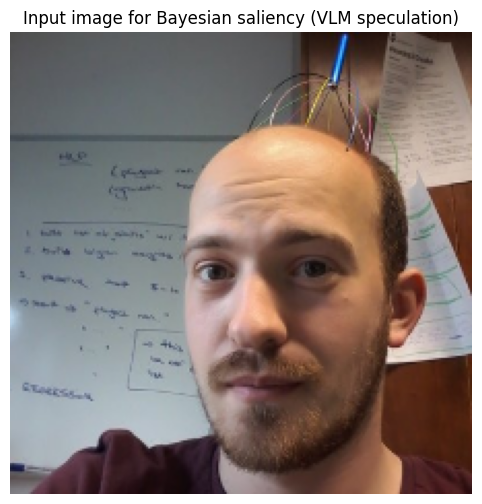

In [7]:
#load input
def load_image_from_url_or_path(image_source, input_size=None):
    if str(image_source).startswith("http"):
        resp = requests.get(image_source, timeout=30)
        img = cv2.imdecode(np.frombuffer(resp.content, np.uint8), cv2.IMREAD_COLOR)
    else:
        img = cv2.imread(image_source)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if input_size is not None:
        img = cv2.resize(img, input_size)
    return img

image_path = "https://pbs.twimg.com/profile_images/776047601816829953/suLLGY-y_400x400.jpg"
img = load_image_from_url_or_path(image_path, input_size=(224, 224))
h, w = img.shape[:2]

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Input image for Bayesian saliency (VLM speculation)")
plt.show()


In [8]:
# Create sampling grid (position, and blanking window size)
x,y,w,h = np.meshgrid(np.linspace(0,32,32),np.linspace(0,32,32),np.linspace(1,8,7),np.linspace(1,8,7))

X = np.vstack((x.ravel(),y.ravel(),w.ravel(),h.ravel())).T

# Storage for samples
Xm = []
fm_dict = {}

# First sample
state = X[np.random.randint(0,X.shape[0]),:].astype(int)
Xm.append(state)


In [9]:
_, _, base_result = infer_image_demographics_with_retry(
    image_source=image_path,
    model_name= "Llama-4-Maverick-17B-128E-Instruct-FP8",
    demo_features=demo_features,
    prefix="Image_Demo",
)

# Build a dict of baseline speculation scores for all demographics
baseline_scores = {}
for demo in demo_features:
    key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
    baseline_scores[key] = base_result.get(key, np.nan)

# Initialize per-feature sample arrays
for key in baseline_scores.keys():
    fm_dict[key] = []

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


In [10]:
h, w = img.shape[:2]
h, w = int(h), int(w)


2025-10-13 01:48:08 | PID 615372 | RSS   325.9 MB | Initialized occlusion grid: X.shape=(28224, 4), initial state=[ 9.39130435 19.82608696 14.          8.        ]


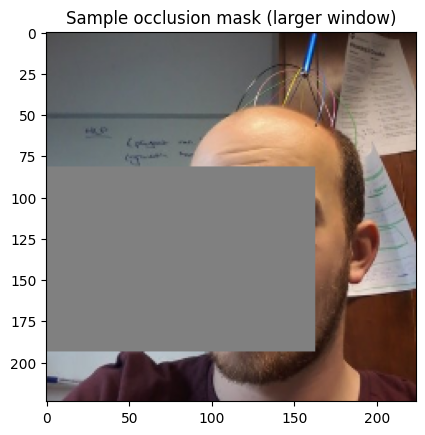

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded
[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


KeyboardInterrupt: 

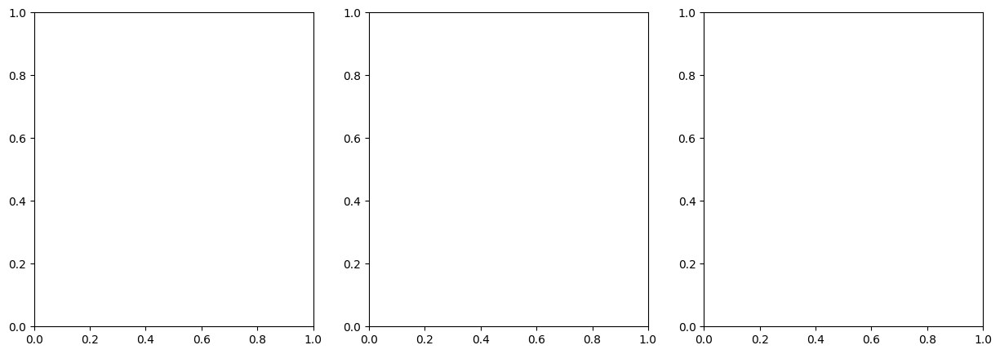

In [ ]:
#version 20:43



# ===============================================================
# CONFIG / LOGGING
# ===============================================================
log_path = os.path.expanduser("~/vlm_debug.log")
pid = os.getpid()
proc = psutil.Process(pid)

logf = open(log_path, "a", buffering=1)

def L(msg):
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    rss = proc.memory_info().rss / (1024 ** 2)
    line = f"{ts} | PID {pid} | RSS {rss:7.1f} MB | {msg}"
    print(line)
    logf.write(line + "\n")

def mark_exit():
    ts = time.strftime("%Y-%m-%d %H:%M:%S")
    logf.write(f"{ts} | PID {pid} | Program terminated cleanly\n")
    logf.close()

atexit.register(mark_exit)

# ===============================================================
# SETTINGS
# ===============================================================
SKIP_VLM = False
max_points = 60
plot_every = 3

# Debug toggles
DEBUG_PRINT_MASKED_RESULT = True
DEBUG_SAVE_MASKED = True
DEBUG_SAVE_EVERY = 10
DEBUG_VERBOSE_FM = True

# ===============================================================
# CREATE SAMPLING GRID WITH LARGER OCCLUSION WINDOWS
# ===============================================================
grid_pos = 32  # defines the grid density

xv, yv, wv, hv = np.meshgrid(
    np.linspace(0, 32, 32),    # allow full width
    np.linspace(0, 32, 32),    # allow full height
    np.linspace(4, 16, 9),     # slightly larger window options
    np.linspace(4, 16, 9),
    indexing="ij"
)


X = np.vstack((xv.ravel(), yv.ravel(), wv.ravel(), hv.ravel())).T

# initialize state
state = X[np.random.randint(0, X.shape[0]), :].astype(float)
Xm = [state]

L(f"Initialized occlusion grid: X.shape={X.shape}, initial state={state}")

# ===============================================================
# SANITY CHECK — visualize initial mask
# ===============================================================
h_img, w_img = img.shape[:2]
scale_x = w_img / grid_pos
scale_y = h_img / grid_pos
x0, y0, ww, hh = state
x1 = int(max(x0*scale_x - ww*scale_x, 0))
x2 = int(min(x0*scale_x + ww*scale_x, w_img))
y1 = int(max(y0*scale_y - hh*scale_y, 0))
y2 = int(min(y0*scale_y + hh*scale_y, h_img))
mask_vis = img.copy()
mask_vis[y1:y2, x1:x2, :] = 128

plt.imshow(mask_vis)
plt.title("Sample occlusion mask (larger window)")
plt.show()

# ===============================================================
# MAIN LOOP
# ===============================================================
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i in range(30):
    try:
        # L(f"ITER {i} start | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion ---
        h_img, w_img = img.shape[:2]
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        # L(f"Occlusion applied: grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) → px=({x1},{y1},{x2},{y2}) patch=({x2-x1}x{y2-y1})")

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))
        # L(f"Saved occluded image to {tmp_path}")

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
            # L("SKIP_VLM enabled — using dummy masked_result")
        else:
            try:
                t0 = time.time()
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=demo_features,
                    prefix="Image_Demo",
                )
                # L(f"VLM call OK in {time.time()-t0:.2f}s; found keys: {list(masked_result.keys())[:6]}")
            except Exception as ex:
                L(f"ERROR during VLM call: {ex}")
                raise

        if DEBUG_PRINT_MASKED_RESULT:
            try:
                sample_items = list(masked_result.items())[:6]
                sample_str = ", ".join([f"{k}:{v}" for k, v in sample_items])
                # L(f"masked_result sample: {sample_str}")
            except Exception as ex:
                L(f"Couldn't stringify masked_result: {ex}")

        try:
            os.remove(tmp_path)
        except Exception:
            pass

        # --- 6.3 Compute deltas ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(float(delta))

            if DEBUG_VERBOSE_FM:
                arr = np.array(fm_dict[key])
                # L(f"fm_dict[{key}] len={len(arr)} mean={arr.mean():.3f} std={arr.std():.3f} last={arr[-1]:.3f}")

        # --- 6.4 Build fm_mean for GP ---
        if len(Xm) == 0:
            state = X[np.random.randint(0, X.shape[0]), :].astype(int)
            Xm.append(state)
            continue

        key_ref = list(fm_dict.keys())[0]
        fm_values_ref = fm_dict[key_ref]
        n = min(len(Xm), len(fm_values_ref))
        fm_mean = np.array(fm_values_ref[:n])

        Xm_arr = np.array(Xm)
        X_norm = X / np.array([32, 32, 8, 8])
        Xm_norm = Xm_arr / np.array([32, 32, 8, 8])

        # --- 6.5 Fit GP ---
        if len(Xm) > max_points:
            Xm = Xm[-max_points:]
            # L(f"Truncated Xm to last {max_points} points")

        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        # L("Shared GP fitted")

        mu, sig = gp.predict(X_norm, return_std=True)
        # L(f"GP predict done | mu_range=({mu.min():.6f},{mu.max():.6f}) | sig_range=({sig.min():.6f},{sig.max():.6f})")

        # --- 6.6 Acquisition ---
        acq = mu + 1.5 * sig
        if np.allclose(acq, acq[0]):
            aq_bin = np.random.randint(len(X))
            # L(f"Acquisition flat — random choice {aq_bin}")
        else:
            aq_bin = int(np.argmax(acq))
        # L(f"Selected aq_bin={aq_bin}")

        # --- 6.7 Update next state ---
        state = X[aq_bin].astype(int)
        Xm.append(state + np.random.randn(4,) * np.array([1, 1, 0.5, 0.5]))
        # L(f"Appended new state {state.tolist()} | Xm len={len(Xm)}")

        # --- 6.8 Visualization ---
        expected = 32 * 32 * 7 * 7
        if mu.size != expected:
            continue

        ov = mu.reshape(32, 32, 7, 7).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(32, 32, -1), -1)
        # --- 6.8 Visualization (flash mask like original) ---
        if i % plot_every == 0:
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
            x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
            y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

            # --- Clear and redraw each axis like original ---
            ax[0].cla()
            ax[0].imshow(masked_img)
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].plot(x_last, y_last, 'r*')
            ax[0].set_title(f"Occlusion sampling — iter {i}")

            ax[1].cla()
            ax[1].imshow(img)
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet")
            ax[1].plot(x_plot, y_plot, '*')
            ax[1].plot(x_last, y_last, 'r*')
            ax[1].set_title("Mean sensitivity")

            ax[2].cla()
            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet")
            ax[2].plot(x_plot, y_plot, '*')
            ax[2].plot(x_last, y_last, 'r*')
            ax[2].set_title("Acquisition function")

            plt.tight_layout()

            # --- This is crucial ---
            display.display(plt.gcf())        # always show the current figure
            display.clear_output(wait=True)   # clear for the next frame
            plt.pause(0.001)



        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

# --- Summary ---
L("=== Finished loop — fm_dict summary ===")
for k, v in fm_dict.items():
    arr = np.array(v)
    L(f"{k:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f} first5={np.round(arr[:5],6)}")

logf.flush()


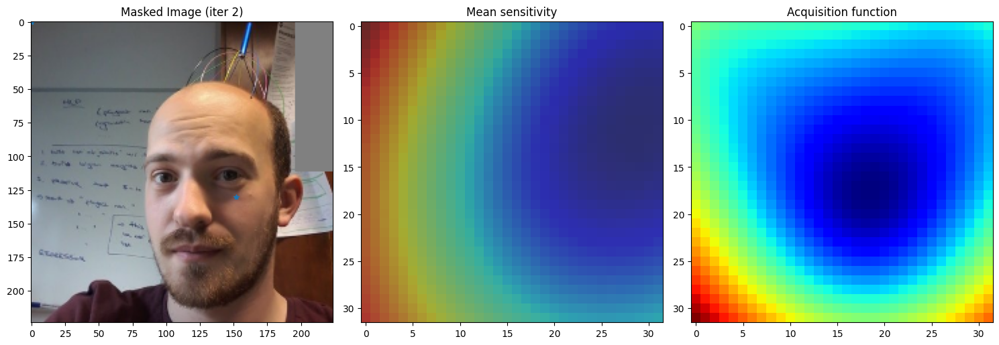

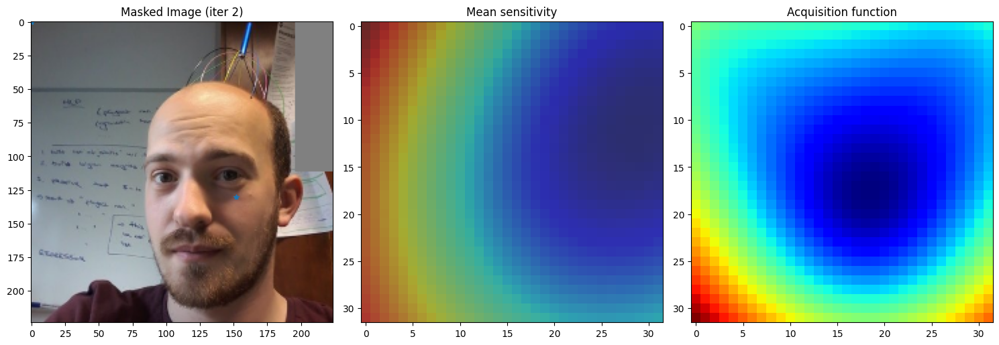

2025-10-13 12:20:15 | PID 615372 | RSS   337.4 MB | 
--- ITER 3 start --- | len(Xm)=4 | len(fm_dict)=6
2025-10-13 12:20:15 | PID 615372 | RSS   337.4 MB | [DEBUG] Mask grid=(0.00,0.00,4.00,16.00) → px=(0,0,28,112) | patch=(28x112)
2025-10-13 12:20:15 | PID 615372 | RSS   337.4 MB | [DEBUG] Mask changed from previous: True | Δ=[-32.   0.   0.   0.]


KeyboardInterrupt: 

In [35]:
# ===============================================================
# CREATE SAMPLING GRID WITH LARGER OCCLUSION WINDOWS
# ===============================================================
grid_pos = 32  # defines the grid density

xv, yv, wv, hv = np.meshgrid(
    np.linspace(0, 32, 32),    # allow full width
    np.linspace(0, 32, 32),    # allow full height
    np.linspace(4, 16, 9),     # slightly larger window options
    np.linspace(4, 16, 9),
    indexing="ij"
)


X = np.vstack((xv.ravel(), yv.ravel(), wv.ravel(), hv.ravel())).T

# initialize state
state = X[np.random.randint(0, X.shape[0]), :].astype(float)
Xm = [state]
# ===============================================================
# MAIN LOOP (with dynamic shape + mask-change debug)
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency loop with dynamic grid + mask debug ===")

# --- Compute grid shape dynamically ---
nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
L(f"[DEBUG] Grid shape: ({nx}, {ny}, {nw}, {nh}) → total={X.shape[0]} points")

prev_state = None  # for mask-change detection

for i in range(30):
    try:
        L(f"\n--- ITER {i} start --- | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion ---
        h_img, w_img = img.shape[:2]
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        L(f"[DEBUG] Mask grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) → px=({x1},{y1},{x2},{y2}) | patch=({x2-x1}x{y2-y1})")

        # --- Detect if mask changed ---
        if prev_state is not None:
            delta = np.round(state - prev_state, 3)
            changed = not np.allclose(state, prev_state)
            L(f"[DEBUG] Mask changed from previous: {changed} | Δ={delta}")
        else:
            L(f"[DEBUG] Initial state={state}")
        prev_state = state.copy()

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
        else:
            t0 = time.time()
            _, _, masked_result = infer_image_demographics_with_retry(
                image_source=tmp_path,
                model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                demo_features=demo_features,
                prefix="Image_Demo",
            )
            L(f"[DEBUG] VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result.keys())[:5]}")

        os.remove(tmp_path)

        # --- 6.3 Compute deltas ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(float(delta))

        # --- 6.4 Build fm_mean for GP ---
        if len(Xm) == 0:
            state = X[np.random.randint(0, X.shape[0]), :].astype(float)
            Xm.append(state)
            continue

        key_ref = list(fm_dict.keys())[0]
        fm_values_ref = fm_dict[key_ref]
        n = min(len(Xm), len(fm_values_ref))
        fm_mean = np.array(fm_values_ref[:n])

        Xm_arr = np.array(Xm)

        # Normalize dynamically based on actual grid max values
        max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])
        X_norm = X / max_vals
        Xm_norm = Xm_arr / max_vals

        if len(Xm) > max_points:
            Xm = Xm[-max_points:]

        # --- 6.5 Fit GP ---
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"[DEBUG] GP predict: mu_range=({mu.min():.4f},{mu.max():.4f}) | sig_range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.6 Acquisition ---
        acq = mu + 1.5 * sig
        acq_max = np.max(acq)
        acq_std = np.std(acq)
        L(f"[DEBUG] acq stats: min={acq.min():.4f} max={acq_max:.4f} mean={acq.mean():.4f} std={acq_std:.4f}")

        # If acquisition surface is flat, force exploration
        if acq_std < 1e-3:
            aq_bin = np.random.randint(len(X))
            L("[DEBUG] Acquisition flat — random exploration triggered")
        else:
            aq_bin = int(np.argmax(acq))

        # --- 6.7 Update state (no rounding!) ---
        prev_state = state.copy()
        state = X[aq_bin].astype(float)
        changed = not np.allclose(state, prev_state)

        # add small random jitter to encourage movement
        if not changed:
            state = state + np.random.randn(4) * np.array([0.5, 0.5, 0.2, 0.2])
            state = np.clip(state, [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                                [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()])
            changed = True
            L("[DEBUG] Forced jitter to break stagnation")

        L(f"[DEBUG] Selected new state={state} | changed={changed}")
        Xm.append(state)
        L(f"[DEBUG] Xm len now {len(Xm)}")

        # --- 6.8 Visualization ---
        # reshape dynamically using your grid shape
        try:
            ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
            sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
        except Exception as ex:
            L(f"[DEBUG] Reshape failed: {ex}")
            continue

        if changed:
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)

            fig, ax = plt.subplots(1, 3, figsize=(15, 5))

            ax[0].imshow(masked_img)
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].set_title(f"Masked Image (iter {i})")

            ax[1].imshow(img)
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet")
            ax[1].set_title("Mean sensitivity")

            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet")
            ax[2].set_title("Acquisition function")

            plt.tight_layout()
            display.clear_output(wait=True)
            display.display(plt.gcf())
            plt.pause(0.1)
            plt.close(fig)

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

# --- Summary ---
L("=== Finished loop — fm_dict summary ===")
for k, v in fm_dict.items():
    arr = np.array(v)
    L(f"{k:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f} first5={np.round(arr[:5],6)}")

logf.flush()


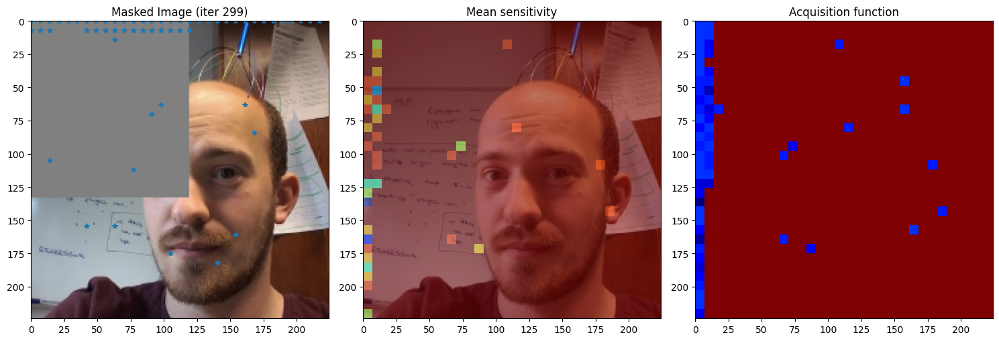

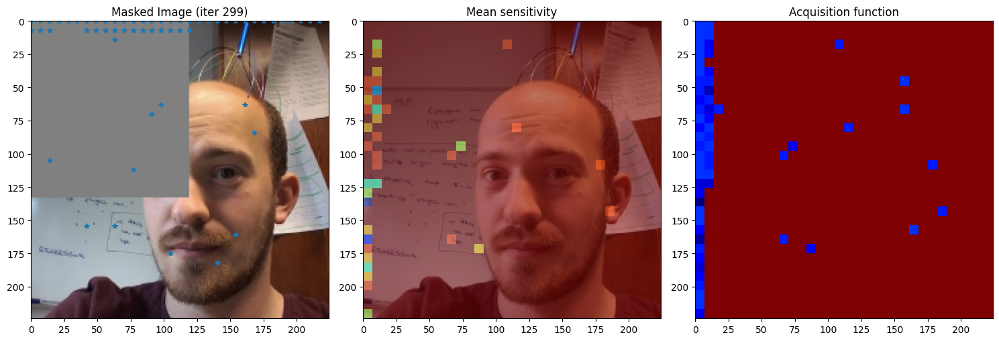

2025-10-13 13:17:38 | PID 615372 | RSS   400.9 MB | === Finished loop — fm_dict summary ===
2025-10-13 13:17:38 | PID 615372 | RSS   400.9 MB | Image_Demo_ethnicity_Speculation                             len=561 mean=-10.347594 std=14.088289 first5=[-20. -10. -21. -50. -10.]
2025-10-13 13:17:38 | PID 615372 | RSS   400.9 MB | Image_Demo_age_Speculation                                   len=561 mean=-12.203209 std=10.029621 first5=[-20. -10. -11. -30. -10.]
2025-10-13 13:17:38 | PID 615372 | RSS   400.9 MB | Image_Demo_sex_Speculation                                   len=561 mean=-4.812834 std=9.016261 first5=[-10.   0.   0.   0.   0.]
2025-10-13 13:17:38 | PID 615372 | RSS   400.9 MB | Image_Demo_highest_educational_qualification_Speculation     len=561 mean=-7.532977 std=12.750285 first5=[-20. -20. -21. -20. -20.]
2025-10-13 13:17:38 | PID 615372 | RSS   400.9 MB | Image_Demo_household_income_bracket_Speculation              len=561 mean=-20.868093 std=8.623047 first5=[-20. -30. -21

In [42]:
# ===============================================================
# CREATE SAMPLING GRID WITH LARGER OCCLUSION WINDOWS
# ===============================================================
grid_pos = 32  # defines the grid density

xv, yv, wv, hv = np.meshgrid(
    np.linspace(0, grid_pos - 1, grid_pos),   # x positions
    np.linspace(0, grid_pos - 1, grid_pos),   # y positions
    np.linspace(4, 16, 9),                    # widths
    np.linspace(4, 16, 9),
    indexing="ij"
)


X = np.vstack((xv.ravel(), yv.ravel(), wv.ravel(), hv.ravel())).T

# initialize state
state = X[np.random.randint(0, X.shape[0]), :].astype(float)
Xm = [state]

# ===============================================================
# MAIN LOOP (with dynamic grid, size diversity, and mask-change debug)
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency loop with size diversity + exploration ===")

# --- Compute grid shape dynamically ---
nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
L(f"[DEBUG] Grid shape: ({nx}, {ny}, {nw}, {nh}) → total={X.shape[0]} points")

prev_state = None  # for mask-change detection

for i in range(300):
    try:
        L(f"\n--- ITER {i} start --- | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion ---
        h_img, w_img = img.shape[:2]
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(x0 * scale_x)
        y0_px = int(y0 * scale_y)
        ww_px = int(ww * scale_x)
        hh_px = int(hh * scale_y)
        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        L(f"[DEBUG] Mask grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) → px=({x1},{y1},{x2},{y2}) | patch=({x2-x1}x{y2-y1})")

        # --- Detect if mask changed ---
        if prev_state is not None:
            delta = np.round(state - prev_state, 3)
            changed = not np.allclose(state, prev_state)
            L(f"[DEBUG] Mask changed from previous: {changed} | Δ={delta}")
        else:
            L(f"[DEBUG] Initial state={state}")
        prev_state = state.copy()

        # --- 6.2 Save occluded image temporarily ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
        else:
            t0 = time.time()
            _, _, masked_result = infer_image_demographics_with_retry(
                image_source=tmp_path,
                model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                demo_features=demo_features,
                prefix="Image_Demo",
            )
            L(f"[DEBUG] VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result.keys())[:5]}")

        os.remove(tmp_path)

        # --- 6.3 Compute deltas ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = base_score - masked_score
            fm_dict.setdefault(key, []).append(float(delta))

        # --- 6.4 GP Training Data ---
        if len(Xm) == 0:
            state = X[np.random.randint(0, X.shape[0]), :].astype(float)
            Xm.append(state)
            continue

        key_ref = list(fm_dict.keys())[0]
        fm_values_ref = fm_dict[key_ref]
        n = min(len(Xm), len(fm_values_ref))
        fm_mean = np.array(fm_values_ref[:n])

        Xm_arr = np.array(Xm)

        # ✅ Improved normalization: treat position & size differently
        pos_scale = np.array([xv.max(), yv.max()])
        size_scale = np.array([8.0, 8.0])  # smaller normalization for w,h
        scale_vec = np.concatenate([pos_scale, size_scale])
        X_norm = X / scale_vec
        Xm_norm = Xm_arr / scale_vec

        if len(Xm) > max_points:
            Xm = Xm[-max_points:]

        # --- 6.5 Fit GP ---
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"[DEBUG] GP predict: mu_range=({mu.min():.4f},{mu.max():.4f}) | sig_range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.6 Acquisition Function ---
        size_bonus = 0.05 * (X[:, 2] + X[:, 3])  # ✅ Encourage larger masks
        acq = mu + 1.5 * sig + size_bonus
        acq_std = np.std(acq)
        L(f"[DEBUG] acq stats: min={acq.min():.4f} max={acq.max():.4f} mean={acq.mean():.4f} std={acq_std:.4f}")

        # ✅ Random exploration if acquisition flat or stuck
        if acq_std < 1e-3:
            aq_bin = np.random.randint(len(X))
            L("[DEBUG] Acquisition flat — random exploration triggered")
        else:
            aq_bin = int(np.argmax(acq))

        prev_state = state.copy()
        state = X[aq_bin].astype(float)
        changed = not np.allclose(state, prev_state)

        # ✅ Stronger jitter, especially for mask size
        if not changed:
            jitter = np.array([0.5, 0.5, 1.0, 1.0]) * np.random.randn(4)
            state = state + jitter
            state = np.clip(
                state,
                [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()]
            )
            changed = True
            L(f"[DEBUG] Forced jitter to break stagnation | Δ={np.round(jitter, 2)}")

        # ✅ Periodic exploration
        if i % 5 == 0 and i > 0:
            L("[DEBUG] Forced exploration: random new mask every 5 iterations")
            state = X[np.random.randint(0, X.shape[0]), :].astype(float)
            changed = True

        L(f"[DEBUG] Selected new state={state} | changed={changed}")
        Xm.append(state)
        L(f"[DEBUG] Xm len now {len(Xm)}")

        # --- 6.7 Visualization ---
        try:
            ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
            sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
        except Exception as ex:
            L(f"[DEBUG] Reshape failed: {ex}")
            continue

        if changed:
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)

            fig, ax = plt.subplots(1, 3, figsize=(15, 5))

            # --- Masked image ---
            ax[0].imshow(masked_img, extent=[0, w_img, h_img, 0])
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].set_title(f"Masked Image (iter {i})")
            ax[0].set_xlim(0, w_img)
            ax[0].set_ylim(h_img, 0)

            # --- Mean sensitivity (overlayed like the original) ---
            ax[1].imshow(img, extent=[0, w_img, h_img, 0])
            ax[1].imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].set_title("Mean sensitivity")
            ax[1].set_xlim(0, w_img)
            ax[1].set_ylim(h_img, 0)

            # --- Acquisition function ---
            ax[2].imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].set_title("Acquisition function")
            ax[2].set_xlim(0, w_img)
            ax[2].set_ylim(h_img, 0)

            plt.tight_layout()
            display.clear_output(wait=True)
            display.display(plt.gcf())
            plt.pause(0.1)
            plt.close(fig)


        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break


# --- Summary ---
L("=== Finished loop — fm_dict summary ===")
for k, v in fm_dict.items():
    arr = np.array(v)
    L(f"{k:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f} first5={np.round(arr[:5],6)}")

logf.flush()


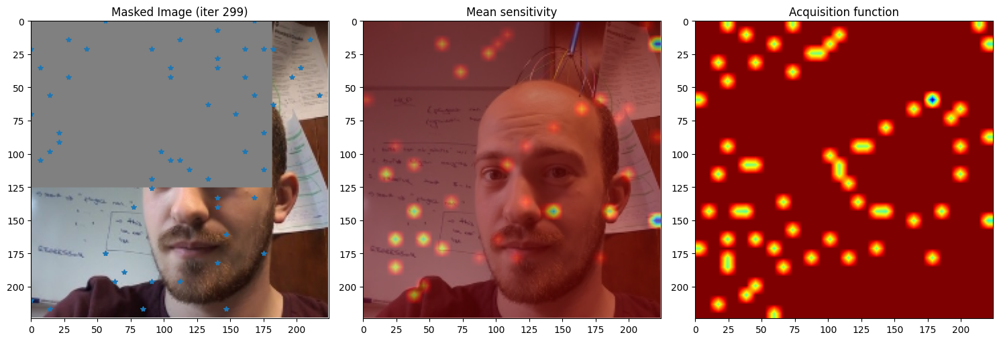

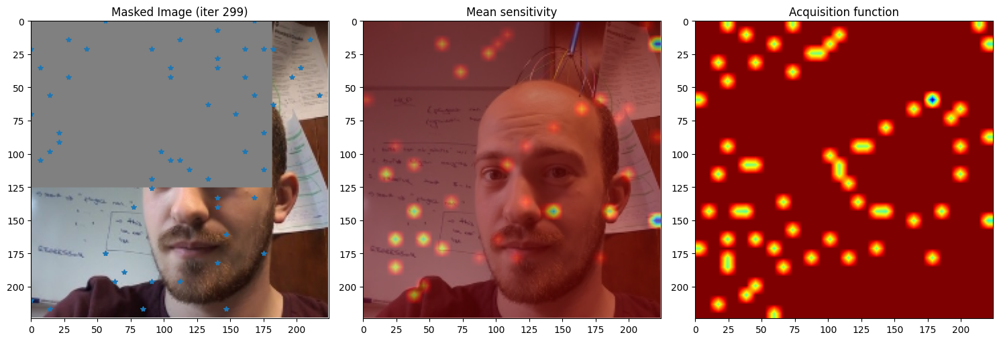

2025-10-13 15:56:58 | PID 615372 | RSS   412.5 MB | === Finished loop — fm_dict summary ===
2025-10-13 15:56:58 | PID 615372 | RSS   412.5 MB | Image_Demo_ethnicity_Speculation                             len=893 mean=-14.311310 std=16.949350 first5=[-20. -10. -21. -50. -10.]
2025-10-13 15:56:58 | PID 615372 | RSS   412.5 MB | Image_Demo_age_Speculation                                   len=893 mean=-14.367301 std=11.692568 first5=[-20. -10. -11. -30. -10.]
2025-10-13 15:56:58 | PID 615372 | RSS   412.5 MB | Image_Demo_sex_Speculation                                   len=893 mean=-7.435610 std=13.895609 first5=[-10.   0.   0.   0.   0.]
2025-10-13 15:56:58 | PID 615372 | RSS   412.5 MB | Image_Demo_highest_educational_qualification_Speculation     len=893 mean=-8.945129 std=13.268876 first5=[-20. -20. -21. -20. -20.]
2025-10-13 15:56:58 | PID 615372 | RSS   412.5 MB | Image_Demo_household_income_bracket_Speculation              len=893 mean=-22.077268 std=8.643212 first5=[-20. -30. -2

In [ ]:
# ===============================================================
# CREATE SAMPLING GRID WITH LARGER OCCLUSION WINDOWS
# ===============================================================
grid_pos = 32  # defines the grid density

xv, yv, wv, hv = np.meshgrid(
    np.linspace(0, grid_pos - 1, grid_pos),   # x positions
    np.linspace(0, grid_pos - 1, grid_pos),   # y positions
    np.linspace(4, 16, 9),                    # widths
    np.linspace(4, 16, 9),
    indexing="ij"
)


X = np.vstack((xv.ravel(), yv.ravel(), wv.ravel(), hv.ravel())).T

# initialize state
state = X[np.random.randint(0, X.shape[0]), :].astype(float)
Xm = [state]
# ===============================================================
# MAIN LOOP (fixed scaling + resizing for plotting)
# ===============================================================

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
L("=== Starting VLM saliency loop (fixed scaling + plotting) ===")

# --- Compute grid shape dynamically (unchanged) ---
nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
L(f"[DEBUG] Grid shape: ({nx}, {ny}, {nw}, {nh}) → total={X.shape[0]} points")

prev_state = None  # for mask-change detection

for i in range(300):
    try:
        L(f"\n--- ITER {i} start --- | len(Xm)={len(Xm)} | len(fm_dict)={len(fm_dict)}")

        # --- 6.1 Apply occlusion ---
        h_img, w_img = img.shape[:2]

        # NOTE: grid defined as np.linspace(0, grid_pos-1, grid_pos)
        # so scale_x = w_img / grid_pos maps grid units -> pixel coordinates consistently.
        scale_x = w_img / grid_pos
        scale_y = h_img / grid_pos

        x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
        x0_px = int(round(x0 * scale_x))
        y0_px = int(round(y0 * scale_y))
        ww_px = int(round(ww * scale_x))
        hh_px = int(round(hh * scale_y))

        x1 = max(x0_px - ww_px, 0)
        y1 = max(y0_px - hh_px, 0)
        x2 = min(x0_px + ww_px, w_img)
        y2 = min(y0_px + hh_px, h_img)
        masked_img = img.copy()
        masked_img[y1:y2, x1:x2, :] = 128

        L(f"[DEBUG] Mask grid=({x0:.2f},{y0:.2f},{ww:.2f},{hh:.2f}) → px=({x1},{y1},{x2},{y2}) | patch=({x2-x1}x{y2-y1})")

        # --- Detect if mask changed ---
        if prev_state is not None:
            delta = np.round(state - prev_state, 3)
            changed = not np.allclose(state, prev_state)
            L(f"[DEBUG] Mask changed from previous: {changed} | Δ={delta}")
        else:
            L(f"[DEBUG] Initial state={state}")
            changed = True
        prev_state = state.copy()

        # --- 6.2 Save occluded image temporarily & query VLM ---
        tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
        os.close(tmp_fd)
        cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

        if SKIP_VLM:
            masked_result = {
                f"Image_Demo_{d['title'].replace(' ','_')}_Speculation": np.random.rand()
                for d in demo_features
            }
        else:
            t0 = time.time()
            _, _, masked_result = infer_image_demographics_with_retry(
                image_source=tmp_path,
                model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                demo_features=demo_features,
                prefix="Image_Demo",
            )
            L(f"[DEBUG] VLM call OK in {time.time()-t0:.2f}s; keys={list(masked_result.keys())[:5]}")

        try:
            os.remove(tmp_path)
        except Exception:
            pass

        # --- 6.3 Compute deltas ---
        for demo in demo_features:
            key = f"Image_Demo_{demo['title'].replace(' ', '_')}_Speculation"
            base_score = baseline_scores.get(key)
            masked_score = masked_result.get(key)
            if base_score is None or masked_score is None:
                continue
            delta = masked_score - base_score
            fm_dict.setdefault(key, []).append(float(delta))

        # --- 6.4 GP Training Data (use first feature as shared proxy) ---
        if len(Xm) == 0:
            state = X[np.random.randint(0, X.shape[0]), :].astype(float)
            Xm.append(state)
            continue

        key_ref = list(fm_dict.keys())[0]
        fm_values_ref = fm_dict[key_ref]
        n = min(len(Xm), len(fm_values_ref))
        fm_mean = np.array(fm_values_ref[:n])

        Xm_arr = np.array(Xm)

        # -----------------------
        # ===== FIXED PART =====
        # -----------------------
        # Normalize using the actual maxima of each grid component:
        # This ensures the GP input space is 0..1 for all dims and consistent with grid.
        max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])  # e.g. [31,31,16,16]
        X_norm = X / max_vals
        Xm_norm = Xm_arr / max_vals
        # -----------------------
        # =======================
        # -----------------------

        if len(Xm) > max_points:
            Xm = Xm[-max_points:]

        # --- 6.5 Fit GP ---
        gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
        gp.fit(Xm_norm, fm_mean)
        mu, sig = gp.predict(X_norm, return_std=True)
        L(f"[DEBUG] GP predict: mu_range=({mu.min():.4f},{mu.max():.4f}) | sig_range=({sig.min():.4f},{sig.max():.4f})")

        # --- 6.6 Acquisition Function (size bonus kept) ---
        size_bonus = 0.05 * (X[:, 2] + X[:, 3])
        acq = mu + 1.5 * sig + size_bonus
        acq_std = np.std(acq)
        L(f"[DEBUG] acq stats: min={acq.min():.4f} max={acq.max():.4f} mean={acq.mean():.4f} std={acq_std:.4f}")

        if acq_std < 1e-3:
            aq_bin = np.random.randint(len(X))
            L("[DEBUG] Acquisition flat — random exploration triggered")
        else:
            # sample stochastically from softmax of acq to avoid deterministic sticking
            probs = np.exp(acq - np.max(acq))
            probs = probs / probs.sum()
            aq_bin = int(np.random.choice(np.arange(len(X)), p=probs))

        prev_state = state.copy()
        state = X[aq_bin].astype(float)
        changed = not np.allclose(state, prev_state)

        # stronger jitter if unchanged
        if not changed:
            jitter = np.array([0.5, 0.5, 1.0, 1.0]) * np.random.randn(4)
            state = state + jitter
            state = np.clip(
                state,
                [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()]
            )
            changed = True
            L(f"[DEBUG] Forced jitter to break stagnation | Δ={np.round(jitter,2)}")

        # periodic random exploration to escape local modes
        if i % 5 == 0 and i > 0:
            state = X[np.random.randint(0, X.shape[0]), :].astype(float)
            changed = True
            L("[DEBUG] Periodic random exploration — new random state chosen")

        L(f"[DEBUG] Selected new state={state} | changed={changed}")
        Xm.append(state)
        L(f"[DEBUG] Xm len now {len(Xm)}")

        # --- 6.7 Visualization ---
        try:
            # reshape using grid dims and then average across window dims
            ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))   # shape (nx, ny)
            sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))  # shape (nx, ny)
        except Exception as ex:
            L(f"[DEBUG] Reshape failed: {ex}")
            continue

        if changed:
            x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
            y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)

            # resize the low-res ov/sxy (nx x ny) to image resolution for clean overlay
            ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)
            sxy_img = cv2.resize(sxy.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)
            acq_img = 5.0 * sxy_img + ov_img

            fig, ax = plt.subplots(1, 3, figsize=(15, 5))

            # --- Masked image (pixel extents) ---
            ax[0].imshow(masked_img)
            ax[0].plot(x_plot, y_plot, '*')
            ax[0].set_title(f"Masked Image (iter {i})")
            ax[0].set_xlim(0, w_img)
            ax[0].set_ylim(h_img, 0)

            # --- Mean sensitivity overlay (resized to image resolution) ---
            ax[1].imshow(img)
            ax[1].imshow(ov_img, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[1].set_title("Mean sensitivity")
            ax[1].set_xlim(0, w_img)
            ax[1].set_ylim(h_img, 0)

            # --- Acquisition function (resized to image resolution) ---
            ax[2].imshow(acq_img, cmap="jet", extent=[0, w_img, h_img, 0])
            ax[2].set_title("Acquisition function")
            ax[2].set_xlim(0, w_img)
            ax[2].set_ylim(h_img, 0)

            plt.tight_layout()
            display.clear_output(wait=True)
            display.display(plt.gcf())
            plt.pause(0.1)
            plt.close(fig)

        gc.collect()

    except Exception as e:
        L(f"ITER {i} exception:\n{traceback.format_exc()}")
        break

# --- Summary ---
L("=== Finished loop — fm_dict summary ===")
for k, v in fm_dict.items():
    arr = np.array(v)
    L(f"{k:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f} first5={np.round(arr[:5],6)}")

logf.flush()



=== Plotting saliency for Image_Demo_ethnicity_Speculation ===
[DEBUG] y_train stats: mean=-13.4918, std=15.8576, min=-70.0000, max=0.0000
[DEBUG] X_train stats: shape=(61, 4), x0_range=(0.000,15.500), y0_range=(0.000,15.500), w_range=(2.000,8.000), h_range=(2.000,8.000)
[DEBUG] mu mean=0.8074, std=0.0165, range=(0.0081,0.9983)
[DEBUG] sig mean=0.2258, std=0.0063, range=(0.0225,0.2265)


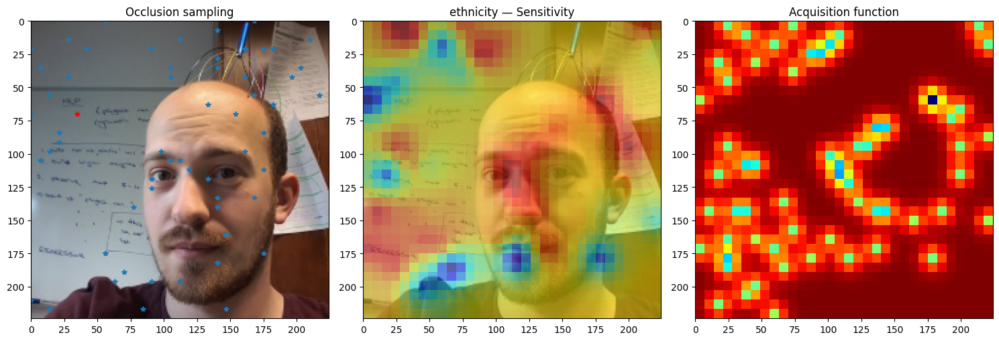


=== Plotting saliency for Image_Demo_age_Speculation ===
[DEBUG] y_train stats: mean=-12.1803, std=10.5683, min=-50.0000, max=10.0000
[DEBUG] X_train stats: shape=(61, 4), x0_range=(0.000,15.500), y0_range=(0.000,15.500), w_range=(2.000,8.000), h_range=(2.000,8.000)
[DEBUG] mu mean=0.6269, std=0.0427, range=(0.0068,0.9960)
[DEBUG] sig mean=0.1699, std=0.0109, range=(0.0175,0.1761)


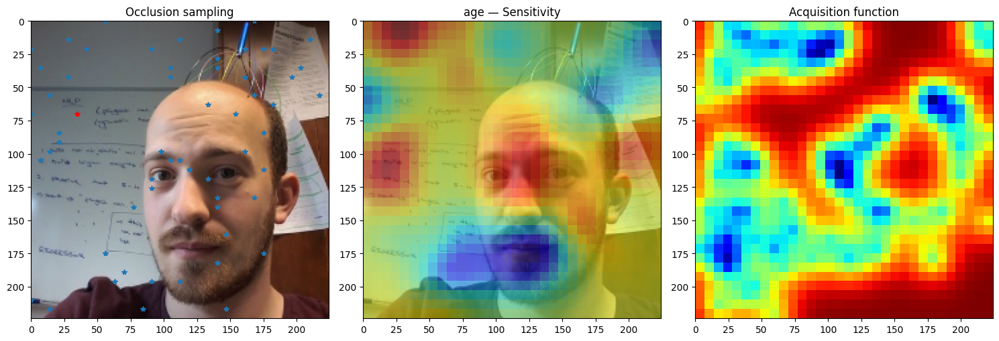


=== Plotting saliency for Image_Demo_sex_Speculation ===
[DEBUG] y_train stats: mean=-6.7213, std=14.3403, min=-90.0000, max=0.0000
[DEBUG] X_train stats: shape=(61, 4), x0_range=(0.000,15.500), y0_range=(0.000,15.500), w_range=(2.000,8.000), h_range=(2.000,8.000)
[DEBUG] mu mean=0.9253, std=0.0043, range=(0.0092,0.9993)
[DEBUG] sig mean=0.1592, std=0.0039, range=(0.0159,0.1593)


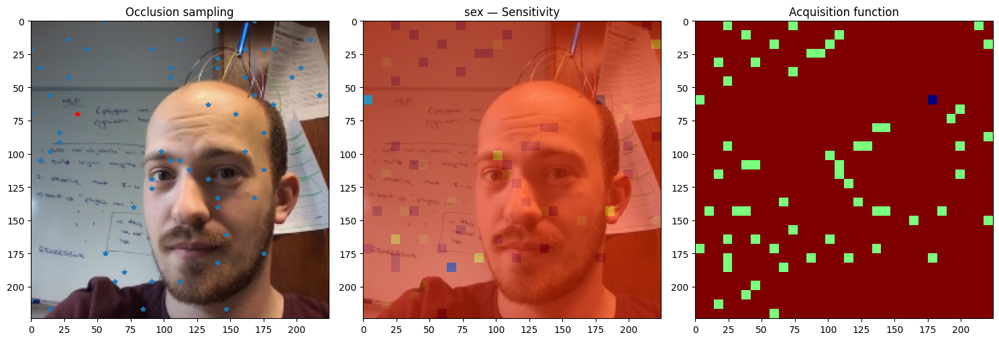


=== Plotting saliency for Image_Demo_highest_educational_qualification_Speculation ===
[DEBUG] y_train stats: mean=-8.7377, std=13.3833, min=-40.0000, max=20.0000
[DEBUG] X_train stats: shape=(61, 4), x0_range=(0.000,15.500), y0_range=(0.000,15.500), w_range=(2.000,8.000), h_range=(2.000,8.000)
[DEBUG] mu mean=0.5251, std=0.0707, range=(0.0045,0.9948)
[DEBUG] sig mean=0.2091, std=0.0179, range=(0.0221,0.2231)


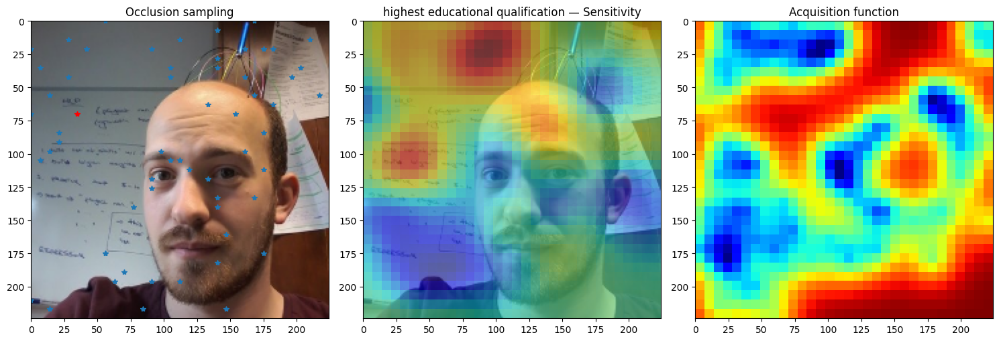


=== Plotting saliency for Image_Demo_household_income_bracket_Speculation ===
[DEBUG] y_train stats: mean=-19.8852, std=8.9646, min=-40.0000, max=0.0000
[DEBUG] X_train stats: shape=(61, 4), x0_range=(0.000,15.500), y0_range=(0.000,15.500), w_range=(2.000,8.000), h_range=(2.000,8.000)
[DEBUG] mu mean=0.5023, std=0.0230, range=(0.0050,0.9952)
[DEBUG] sig mean=0.2228, std=0.0071, range=(0.0223,0.2241)


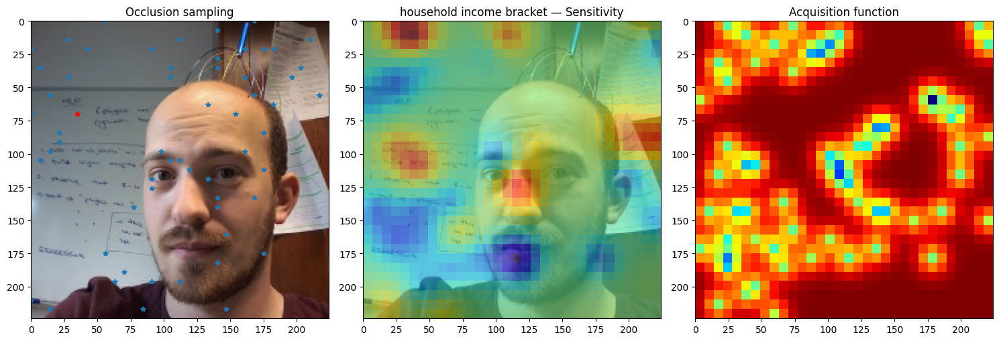


=== Plotting saliency for Image_Demo_partisan_loyalties_Speculation ===
[DEBUG] y_train stats: mean=0.3279, std=1.7808, min=0.0000, max=10.0000
[DEBUG] X_train stats: shape=(61, 4), x0_range=(0.000,15.500), y0_range=(0.000,15.500), w_range=(2.000,8.000), h_range=(2.000,8.000)
[DEBUG] mu mean=0.0278, std=0.0388, range=(-0.0247,0.9902)
[DEBUG] sig mean=0.1709, std=0.0116, range=(0.0176,0.1781)


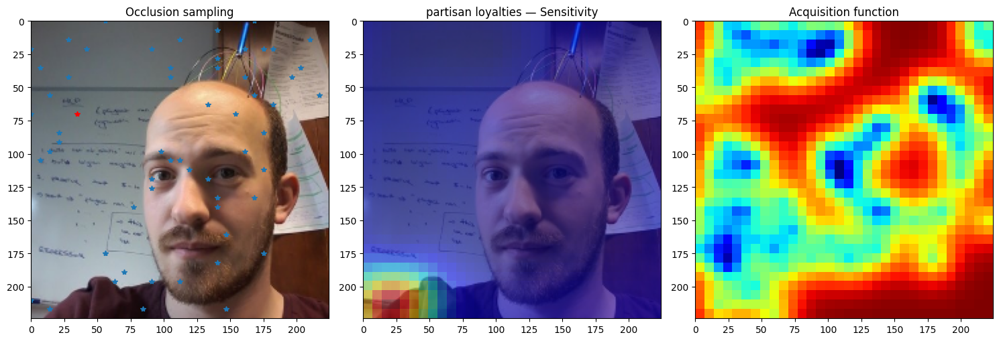

In [48]:
# ============================================================
# 9. Visualize saliency and acquisition per demographic feature (fixed + debug)
# ============================================================

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
import matplotlib.pyplot as plt
from IPython import display
import numpy as np

h_img, w_img = img.shape[:2]
scale_x = w_img / 32.0
scale_y = h_img / 32.0

for key, fm_values in fm_dict.items():
    if len(fm_values) < 2:
        continue

    print(f"\n=== Plotting saliency for {key} ===")
    n = min(len(Xm), len(fm_values))
    X_train = np.array(Xm[:n]) / np.array([2, 2, 2, 2])  # expanded normalization
    y_train = np.array(fm_values[:n])

    print(f"[DEBUG] y_train stats: mean={y_train.mean():.4f}, std={y_train.std():.4f}, "
          f"min={y_train.min():.4f}, max={y_train.max():.4f}")
    print(f"[DEBUG] X_train stats: shape={X_train.shape}, "
          f"x0_range=({X_train[:,0].min():.3f},{X_train[:,0].max():.3f}), "
          f"y0_range=({X_train[:,1].min():.3f},{X_train[:,1].max():.3f}), "
          f"w_range=({X_train[:,2].min():.3f},{X_train[:,2].max():.3f}), "
          f"h_range=({X_train[:,3].min():.3f},{X_train[:,3].max():.3f})")

    # Normalize target to [0,1]
    y_min, y_max = y_train.min(), y_train.max()
    if y_max != y_min:
        y_train = (y_train - y_min) / (y_max - y_min)
    else:
        y_train = np.zeros_like(y_train)

    kernel = Matern(length_scale_bounds=(1e-6, 1e4), nu=1.5)
    gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-2, normalize_y=True)
    gp.fit(X_train, y_train)

    X_norm = X / np.array([2, 2, 2, 2])
    mu, sig = gp.predict(X_norm, return_std=True)

    print(f"[DEBUG] mu mean={mu.mean():.4f}, std={mu.std():.4f}, range=({mu.min():.4f},{mu.max():.4f})")
    print(f"[DEBUG] sig mean={sig.mean():.4f}, std={sig.std():.4f}, range=({sig.min():.4f},{sig.max():.4f})")

    nx = len(np.unique(xv))
    ny = len(np.unique(yv))
    nw = len(np.unique(wv))
    nh = len(np.unique(hv))

    ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))


    # Plot
    x_plot = np.clip(np.array(Xm)[:-2, 1] * scale_x, 0, w_img - 1)
    y_plot = np.clip(np.array(Xm)[:-2, 0] * scale_y, 0, h_img - 1)
    x_last = np.clip(np.array(Xm)[-2, 1] * scale_x, 0, w_img - 1)
    y_last = np.clip(np.array(Xm)[-2, 0] * scale_y, 0, h_img - 1)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img, extent=[0, w_img, h_img, 0])
    ax[0].plot(x_plot, y_plot, '*')
    ax[0].plot(x_last, y_last, 'r*')
    ax[0].set_xlim(0, w_img); ax[0].set_ylim(h_img, 0)
    ax[0].set_title("Occlusion sampling")

    ax[1].imshow(img, extent=[0, w_img, h_img, 0])
    ax[1].imshow(ov.T, alpha=0.5, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[1].set_xlim(0, w_img); ax[1].set_ylim(h_img, 0)
    ax[1].set_title(f"{key.replace('Image_Demo_', '').replace('_Speculation', '').replace('_', ' ')} — Sensitivity")

    ax[2].imshow(5 * sxy.T + ov.T, cmap='jet', extent=[0, w_img, h_img, 0])
    ax[2].set_xlim(0, w_img); ax[2].set_ylim(h_img, 0)
    ax[2].set_title("Acquisition function")

    plt.tight_layout()
    display.display(fig)
    plt.close(fig)


In [59]:
def run_saliency_for_feature(demo_feature, img, baseline_scores):
    """
    Run a full occlusion+GP loop for one demographic feature.
    Saves and displays its own saliency maps.
    """
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")

    # Reinitialize per-feature storage
    fm_dict = {feature_key: []}
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]
    prev_state = None

    # Cache some constants
    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])

    for i in range(30): 
        try:
            # --- Mask application ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))
            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)
            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- Model call ---
            if SKIP_VLM:
                masked_score = np.random.rand()
            else:
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                masked_score = masked_result.get(feature_key)

            try: os.remove(tmp_path)
            except: pass

            # --- Delta ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None or masked_score is None:
                continue
            delta = masked_score - base_score
            fm_dict[feature_key].append(float(delta))

            # --- Prepare GP data ---
            fm_mean = np.array(fm_dict[feature_key])
            Xm_arr = np.array(Xm)
            X_norm = X / max_vals
            Xm_norm = Xm_arr / max_vals

            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_norm, fm_mean)
            mu, sig = gp.predict(X_norm, return_std=True)

            # --- Acquisition ---
            acq = mu + 1.5 * sig + 0.05 * (X[:, 2] + X[:, 3])
            acq_std = np.std(acq)
            if acq_std < 1e-3:
                aq_bin = np.random.randint(len(X))
            else:
                probs = np.exp(acq - np.max(acq))
                probs = probs / probs.sum()
                aq_bin = int(np.random.choice(np.arange(len(X)), p=probs))

            prev_state = state.copy()
            state = X[aq_bin].astype(float)
            if np.allclose(state, prev_state):
                state += np.random.randn(4) * [0.5, 0.5, 1.0, 1.0]
                state = np.clip(state,
                                [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                                [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()])

            Xm.append(state)

            # --- Visualization every few iterations ---
            if i % 1 == 0:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                acq_img = cv2.resize((5*sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # Save summary
    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")



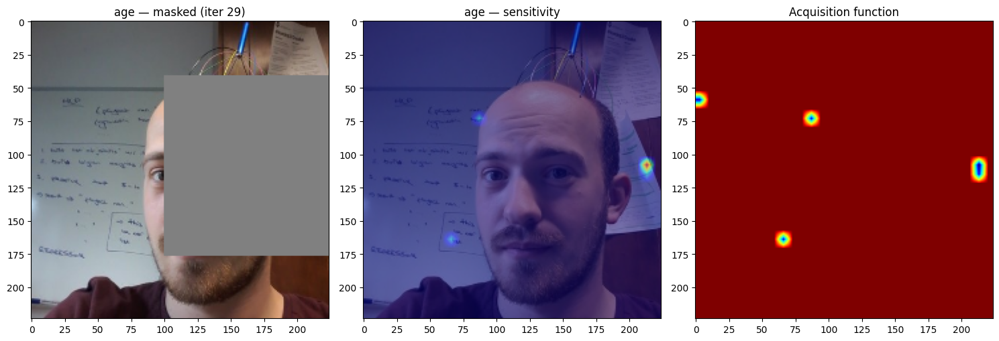

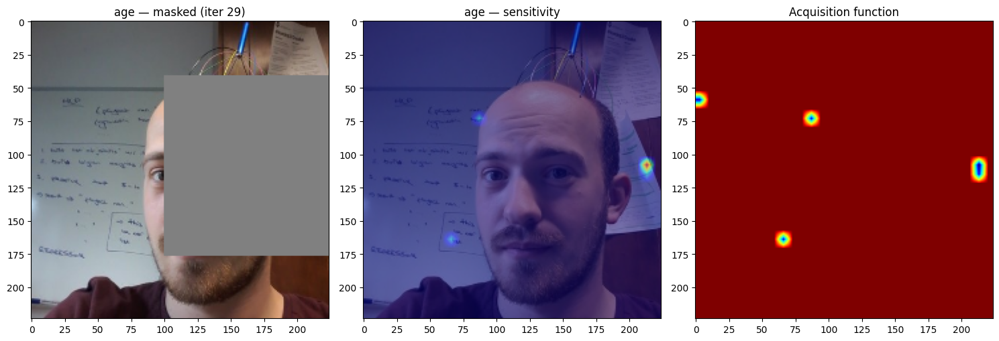

2025-10-13 17:54:49 | PID 615372 | RSS   557.5 MB | age                                                          len= 30 mean=26.333333 std=9.122621


In [60]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


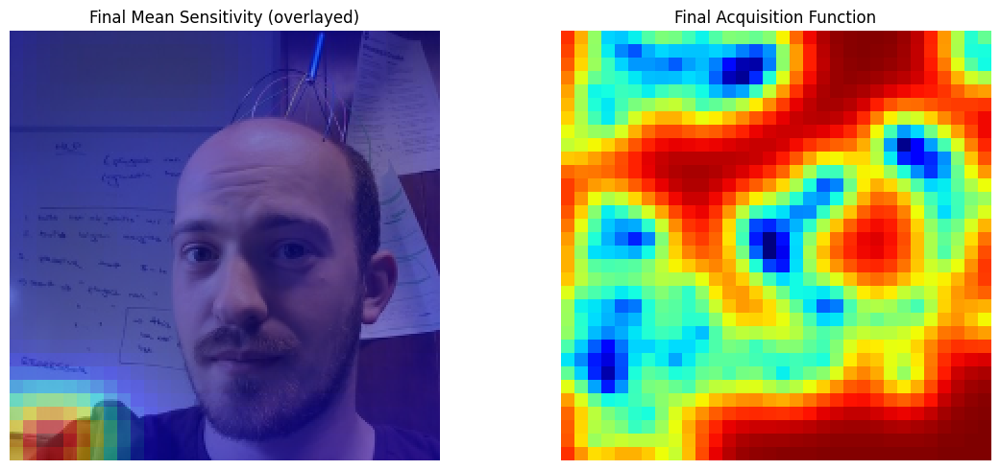

In [63]:

# === Step 9: Post-hoc visualization of the final saliency result ===
try:
    ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
except Exception as ex:
    print(f"[DEBUG] Reshape failed: {ex}")
    raise

plt.figure(figsize=(12, 5))

# --- Mean sensitivity map (overlayed on the image) ---
plt.subplot(1, 2, 1)
plt.imshow(img, extent=[0, w_img, h_img, 0])
plt.imshow(ov.T, alpha=0.5, cmap="jet", extent=[0, w_img, h_img, 0])
plt.title("Final Mean Sensitivity (overlayed)")
plt.axis("off")

# --- Acquisition function map ---
plt.subplot(1, 2, 2)
plt.imshow(5 * sxy.T + ov.T, cmap="jet", extent=[0, w_img, h_img, 0])
plt.title("Final Acquisition Function")
plt.axis("off")

plt.tight_layout()
plt.show()


DEBUG shapes: mu.size= 82944  expected= 82944
DEBUG mu range: -0.024726168543189146 0.9901674753876117
DEBUG sig range: 0.017640278773258265 0.17807825362498722
DEBUG ov.shape, sxy.shape: (32, 32) (32, 32)
DEBUG display vmin/vmax for ov: 0.0167/0.1306
DEBUG display vmin/vmax for acq: 66.1522/72.0462


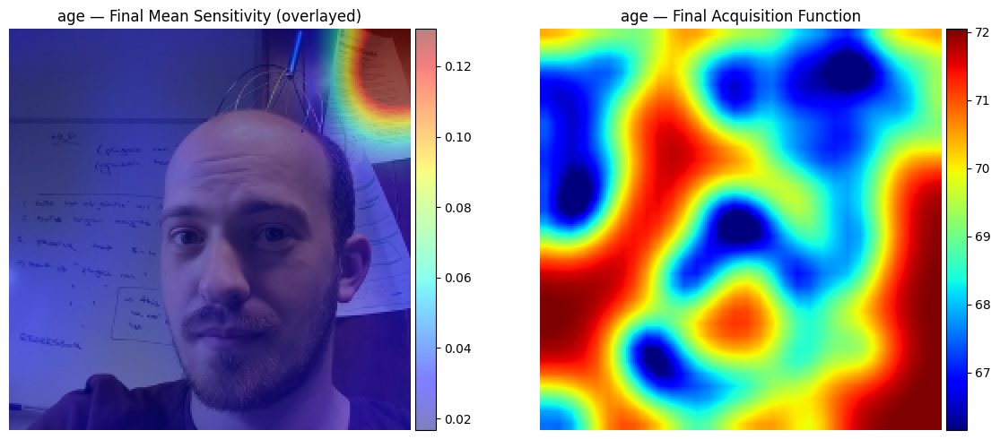

In [62]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter  # pip install scipy if missing

# --- Inputs (must exist after your per-feature run) ---
# mu, sig        : arrays returned by gp.predict for the feature (size = nx*ny*nw*nh)
# nx, ny, nw, nh : grid dims used in reshape
# img            : original image (H, W, 3)
# w_img, h_img   : width, height (or derive from img.shape)
# feature_title  : string name for title (optional)

h_img, w_img = img.shape[:2]
feature_title = "age"  # set to the feature you just ran

# Debug prints: shapes & ranges
print("DEBUG shapes: mu.size=", getattr(mu, "size", None), " expected=", nx*ny*nw*nh)
print("DEBUG mu range:", np.nanmin(mu), np.nanmax(mu))
print("DEBUG sig range:", np.nanmin(sig), np.nanmax(sig))

# 1) reshape the GP mean & std into grid (nx, ny, nw, nh) => average over window sizes (last two dims)
try:
    ov = mu.reshape((nx, ny, nw, nh)).mean(axis=(-1, -2))   # ov.shape == (nx, ny)
    sxy = sig.reshape((nx, ny, nw, nh)).sum(axis=(-1, -2))  # sxy.shape == (nx, ny)
except Exception as e:
    raise RuntimeError(f"Reshape failed: {e}")

print("DEBUG ov.shape, sxy.shape:", ov.shape, sxy.shape)

# 2) optional smoothing to reduce speckle (small sigma smooths noise)
SMOOTH_SIGMA = 1.0  # try 0.0 (no smoothing), 1.0 or 1.5
if SMOOTH_SIGMA > 0:
    ov_s = gaussian_filter(ov, sigma=SMOOTH_SIGMA)
    sxy_s = gaussian_filter(sxy, sigma=SMOOTH_SIGMA)
else:
    ov_s = ov.copy()
    sxy_s = sxy.copy()

# 3) Resize the low-res maps to image pixel size (width, height).
#    Note: cv2.resize expects (width, height) ordering for the target.
ov_img = cv2.resize(ov_s, (w_img, h_img), interpolation=cv2.INTER_LINEAR)
sxy_img = cv2.resize(sxy_s, (w_img, h_img), interpolation=cv2.INTER_LINEAR)

# 4) Normalize for display (optional: use percentile to avoid outliers controlling color)
vmin = np.percentile(ov_img.ravel(), 2)
vmax = np.percentile(ov_img.ravel(), 98)
print(f"DEBUG display vmin/vmax for ov: {vmin:.4f}/{vmax:.4f}")

# 5) Build acquisition image (same scaling)
acq_img = 5.0 * sxy_img + ov_img
acq_vmin = np.percentile(acq_img.ravel(), 2)
acq_vmax = np.percentile(acq_img.ravel(), 98)
print(f"DEBUG display vmin/vmax for acq: {acq_vmin:.4f}/{acq_vmax:.4f}")

# 6) Plot overlay and acquisition side-by-side (use origin='upper' default -> matches image)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.imshow(img)                            # base image
im = ax.imshow(ov_img, alpha=0.5, cmap="jet",
               vmin=vmin, vmax=vmax)      # overlay (already resized)
ax.set_title(f"{feature_title} — Final Mean Sensitivity (overlayed)")
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.01)

ax = axes[1]
im2 = ax.imshow(acq_img, cmap="jet", vmin=acq_vmin, vmax=acq_vmax)
ax.set_title(f"{feature_title} — Final Acquisition Function")
ax.axis("off")
plt.colorbar(im2, ax=ax, fraction=0.046, pad=0.01)

plt.tight_layout()
plt.show()


In [65]:
print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
print("fm_dict lengths per feature:")
for k,v in fm_dict.items():
    print(k, len(v), " mean:", np.mean(v))
print("mu mean/std:", mu.mean(), mu.std())
print("sig mean/std:", sig.mean(), sig.std())


Xm sample ranges (first 10):
 [[28.   9.   4.  10. ]
 [28.  16.  11.5 10. ]
 [20.  20.  10.  14.5]
 [16.  25.   8.5 13. ]
 [ 5.  20.  11.5 10. ]
 [ 8.   2.   7.  13. ]
 [ 5.  29.   4.  16. ]
 [ 6.  15.  13.  16. ]
 [17.  19.  16.  10. ]
 [ 2.  30.  14.5 14.5]]
fm_dict lengths per feature:
Image_Demo_ethnicity_Speculation 893  mean: -14.311310190369541
Image_Demo_age_Speculation 893  mean: -14.367301231802912
Image_Demo_sex_Speculation 893  mean: -7.435610302351623
Image_Demo_highest_educational_qualification_Speculation 893  mean: -8.945128779395297
Image_Demo_household_income_bracket_Speculation 893  mean: -22.07726763717805
Image_Demo_partisan_loyalties_Speculation 893  mean: 0.425531914893617
mu mean/std: 0.027795319936312603 0.03882110439765364
sig mean/std: 0.1709140908723789 0.011632709462867838


In [67]:
def run_saliency_for_feature(demo_feature, img, baseline_scores):
    """
    Run a full occlusion+GP loop for one demographic feature.
    Saves and displays its own saliency maps and prints debug summaries.
    """
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")
    L("[INFO] Using speculation-style delta (masked - base)")

    # Reinitialize per-feature storage
    fm_dict = {feature_key: []}
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]
    prev_state = None

    # Cache some constants
    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])

    for i in range(30):
        try:
            # --- Mask application ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))
            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)
            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- Model call ---
            if SKIP_VLM:
                masked_score = np.random.rand()
            else:
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                masked_score = masked_result.get(feature_key)

            try:
                os.remove(tmp_path)
            except:
                pass

            # --- Delta computation (speculation-style) ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None or masked_score is None:
                continue
            delta = masked_score - base_score  # ✅ correct for speculation
            fm_dict[feature_key].append(float(delta))

            # --- Prepare GP data ---
            fm_mean = np.array(fm_dict[feature_key])
            Xm_arr = np.array(Xm)
            X_norm = X / max_vals
            Xm_norm = Xm_arr / max_vals

            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_norm, fm_mean)
            mu, sig = gp.predict(X_norm, return_std=True)

            # --- Acquisition ---
            acq = mu + 1.5 * sig + 0.05 * (X[:, 2] + X[:, 3])
            acq_std = np.std(acq)
            if acq_std < 1e-3:
                aq_bin = np.random.randint(len(X))
            else:
                probs = np.exp(acq - np.max(acq))
                probs /= probs.sum()
                aq_bin = int(np.random.choice(np.arange(len(X)), p=probs))

            prev_state = state.copy()
            state = X[aq_bin].astype(float)
            if np.allclose(state, prev_state):
                jitter = np.random.randn(4) * [0.5, 0.5, 1.0, 1.0]
                state += jitter
                state = np.clip(
                    state,
                    [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                    [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()]
                )

            Xm.append(state)

            # --- Visualization every few iterations ---
            if i % 5 == 0:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                acq_img = cv2.resize((5*sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # === Final visualization after loop ends ===
    try:
        ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
        sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
        ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)
        acq_img = cv2.resize((5*sxy.T + ov.T).astype(np.float32), (w_img, h_img))

        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        ax[0].imshow(img)
        ax[0].imshow(ov_img, alpha=0.5, cmap="jet")
        ax[0].set_title(f"FINAL — {feature_name} Sensitivity Map")

        ax[1].imshow(acq_img, cmap="jet")
        ax[1].set_title("FINAL — Acquisition Function")

        plt.tight_layout()
        display.display(plt.gcf())
        plt.close(fig)
    except Exception as ex:
        L(f"[DEBUG] Final visualization failed: {ex}")

    # === Print debug summaries ===
    try:
        print("\n--- FINAL DEBUG SUMMARY ---")
        if len(Xm) > 0:
            print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
        print("fm_dict lengths per feature:")
        for k, v in fm_dict.items():
            print(k, len(v), " mean:", np.mean(v) if len(v) > 0 else "N/A")
        print("mu mean/std:", mu.mean() if len(mu) > 0 else "N/A", mu.std() if len(mu) > 0 else "N/A")
        print("sig mean/std:", sig.mean() if len(sig) > 0 else "N/A", sig.std() if len(sig) > 0 else "N/A")
    except Exception as ex:
        print("[DEBUG] Summary print failed:", ex)

    # Save summary to log
    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


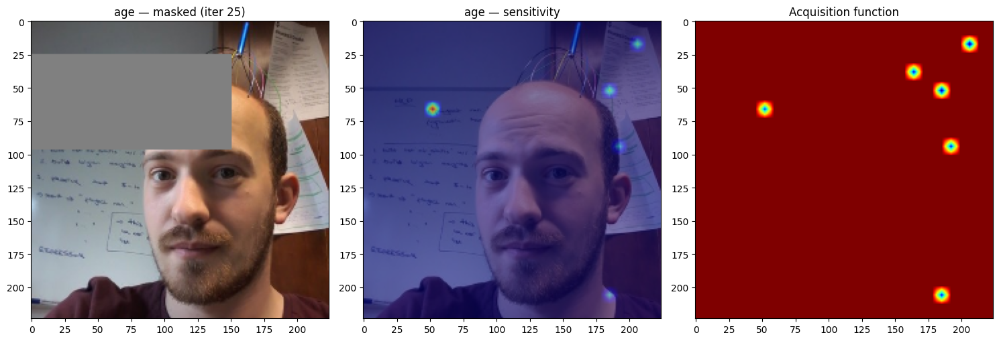

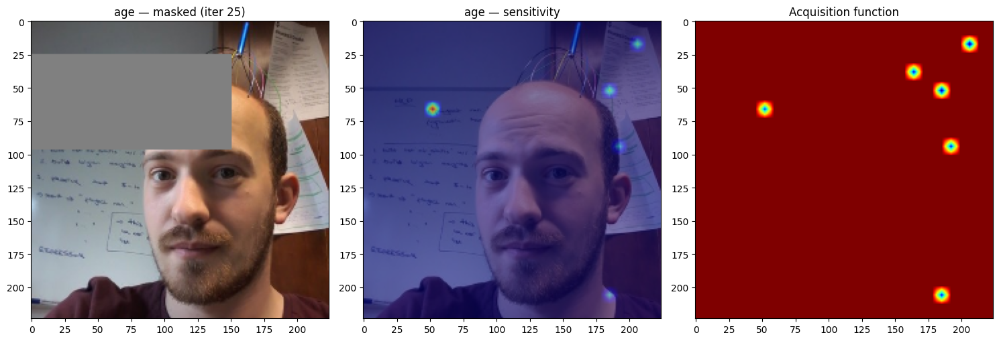

[DEBUG] Found 2 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Found 5 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


[DEBUG] Found 5 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


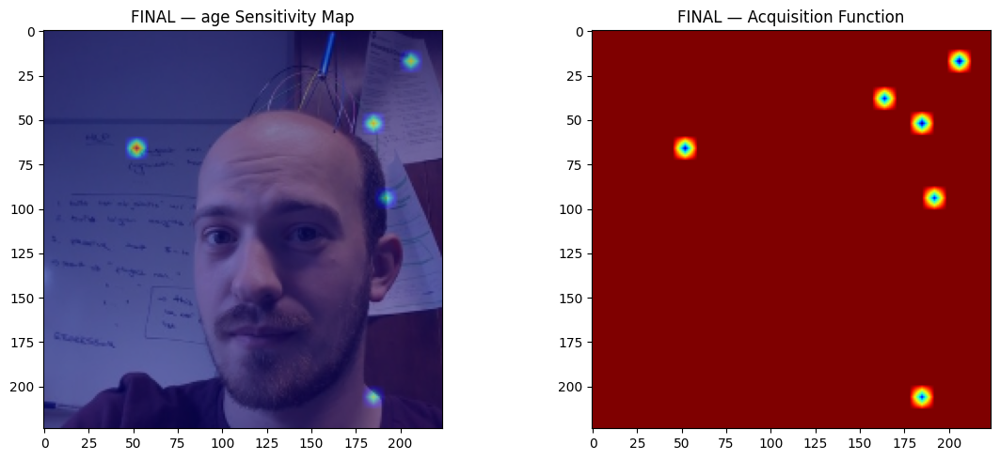


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[29.          2.          8.5         8.5       ]
 [23.          5.         11.5         4.        ]
 [29.          2.          8.5         8.5       ]
 [29.10546479  2.811465    8.39922193  7.89897409]
 [29.          2.          8.5         8.5       ]
 [29.35764765  2.68378462  8.52064107  7.09832379]
 [29.          2.          8.5         8.5       ]
 [28.9177681   2.45403888  9.16246466  9.29262568]
 [29.          2.          8.5         8.5       ]
 [29.07192125  1.65214317  8.8752017   7.04049714]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 16.666666666666668
mu mean/std: 0.0007878459416061723 0.10551527759453172
sig mean/std: 0.9999393133856792 0.007152372712249425
2025-10-13 18:12:13 | PID 615372 | RSS   554.8 MB | age                                                          len= 30 mean=16.666667 std=9.775252


In [68]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


In [72]:
def run_saliency_for_feature(demo_feature, img, baseline_scores):
    """
    Run a full occlusion+GP loop for one demographic feature.
    Adds exploration bias to fix mask stagnation.
    """
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")
    fm_dict = {feature_key: []}
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]
    prev_state = None

    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])

    for i in range(30):
        try:
            # --- Mask ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))
            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)
            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- Model call ---
            if SKIP_VLM:
                masked_score = np.random.rand()
            else:
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                masked_score = masked_result.get(feature_key)

            try: os.remove(tmp_path)
            except: pass

            base_score = baseline_scores.get(feature_key)
            if base_score is None or masked_score is None:
                continue
            delta = masked_score - base_score
            fm_dict[feature_key].append(float(delta))

            fm_mean = np.array(fm_dict[feature_key])
            Xm_arr = np.array(Xm)
            X_norm = X / max_vals
            Xm_norm = Xm_arr / max_vals

            # --- GP ---
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_norm, fm_mean)
            mu, sig = gp.predict(X_norm, return_std=True)

            # --- Acquisition (add exploration bias) ---
            acq = mu + 1.5 * sig + 0.05 * (X[:, 2] + X[:, 3])
            # ✅ Add exploration penalty for over-sampled zones
            if len(Xm) > 5:
                dist = np.min(np.linalg.norm(X[:, None, :] - np.array(Xm)[None, :, :], axis=-1), axis=1)
                acq += 0.1 * dist  # reward distant regions

            acq_std = np.std(acq)
            if acq_std < 1e-3:
                aq_bin = np.random.randint(len(X))
            else:
                aq_bin = int(np.argmax(acq))

            prev_state = state.copy()
            state = X[aq_bin].astype(float)

            # --- Exploration triggers ---
            if np.allclose(state, prev_state) or sig.std() < 0.05:
                jitter = np.random.randn(4) * [1.5, 1.5, 2.0, 2.0]
                state += jitter
                state = np.clip(
                    state,
                    [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                    [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()]
                )
                L(f"[DEBUG] Forced exploration jitter Δ={np.round(jitter,2)}")

            if i % 6 == 0 and i > 0:
                rand_state = X[np.random.randint(0, X.shape[0]), :].astype(float)
                L("[DEBUG] Periodic random exploration injected")
                state = rand_state

            Xm.append(state)

            # --- Visualization ---
            if i % 1 == 0:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                acq_img = cv2.resize((5*sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- Final summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())

    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


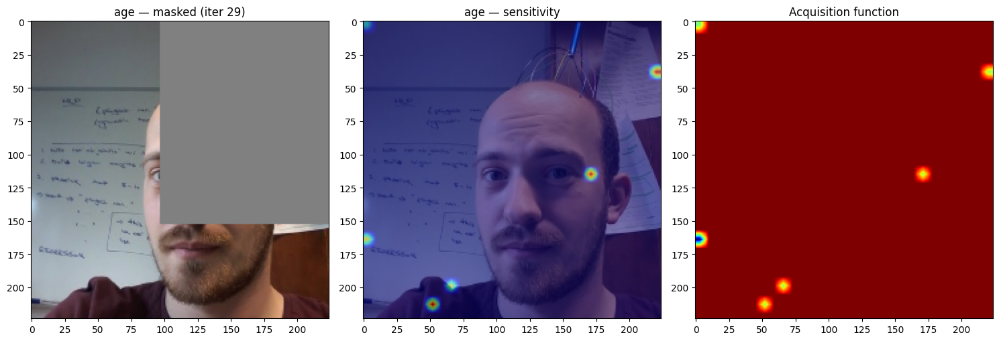

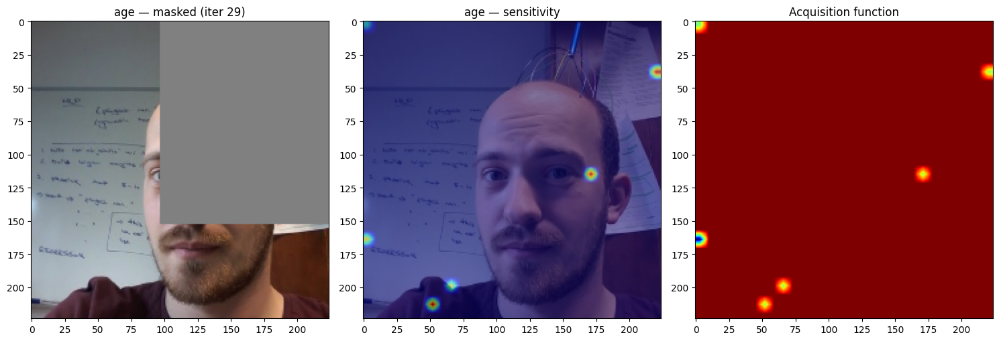


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[ 0.         23.         13.          8.5       ]
 [ 0.         23.         14.5        10.        ]
 [ 0.         23.89025982 16.         15.7132994 ]
 [31.          1.1077602  16.         16.        ]
 [31.          1.46305637 16.         16.        ]
 [31.          5.         16.         16.        ]
 [31.          5.27204664 15.36266749 15.33916493]
 [ 7.         30.          7.          7.        ]
 [30.14366632  6.36196429 16.         16.        ]
 [29.28876271  6.18975758 15.05839402 13.41407974]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 21.333333333333332
mu mean/std: 0.0016075102880658435 0.1928157824836486
sig mean/std: 0.9999340220538151 0.007181644997967288
2025-10-13 18:26:53 | PID 615372 | RSS   582.6 MB | age                                                          len= 30 mean=21.333333 std=8.055364


In [73]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


In [74]:
def run_saliency_for_feature(demo_feature, img, baseline_scores, n_iter=30):
    """
    Run a full occlusion + GP loop for one demographic feature.
    Fixes applied:
      - standardize fm_mean (targets) before GP.fit (handles 0-100 scale)
      - stronger exploration: acq = mu + 2.5*sig + size_bonus
    Shows intermediate visualizations and prints a final debug summary.

    Arguments:
      demo_feature: one element from demo_features (dict with "title")
      img: HxWx3 RGB numpy image
      baseline_scores: dict mapping feature_key -> baseline numeric score
      n_iter: number of occlusion iterations to run
    """
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")
    L("[INFO] Using speculation-style delta (masked - base); standardizing targets for GP")

    # per-feature storage
    fm_dict = {feature_key: []}
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state.copy()]
    prev_state = None

    # grid shape and image constants
    nx = len(np.unique(xv)); ny = len(np.unique(yv)); nw = len(np.unique(wv)); nh = len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / float(grid_pos)
    scale_y = h_img / float(grid_pos)
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()]).astype(float)

    # main loop
    for i in range(n_iter):
        try:
            # --- Mask coords (grid -> pixels) ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))

            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)

            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            # temp save
            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- Model call (single feature) ---
            if SKIP_VLM:
                masked_score = np.random.rand() * 100.0  # same scale-ish if you want
            else:
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                masked_score = masked_result.get(feature_key)
            try:
                os.remove(tmp_path)
            except Exception:
                pass

            # --- Delta (speculation-style) ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None or masked_score is None:
                L(f"[WARN] missing base or masked score for {feature_key}; skipping iter")
                continue
            delta = float(masked_score) - float(base_score)
            fm_dict[feature_key].append(delta)

            # --- Build GP training arrays (normalize X by max_vals) ---
            fm_mean = np.array(fm_dict[feature_key], dtype=float)
            Xm_arr = np.array(Xm, dtype=float)
            X_norm = X / max_vals  # shape (grid_points,4)
            Xm_norm = Xm_arr / max_vals  # shape (n_samples,4)

            # --- Standardize targets: crucial fix for 0-100 speculation scale ---
            if fm_mean.size > 1 and np.std(fm_mean) > 1e-8:
                y_train = (fm_mean - fm_mean.mean()) / (fm_mean.std() + 1e-12)
            else:
                # not enough samples or zero-variance -> keep as-is (GP will still run)
                y_train = fm_mean.copy()

            # --- Fit GP ---
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_norm, y_train)
            mu, sig = gp.predict(X_norm, return_std=True)

            # --- Acquisition: more aggressive exploration by increasing sig weight ---
            size_bonus = 0.05 * (X[:, 2] + X[:, 3])
            acq = mu + 2.5 * sig + size_bonus  # <-- changed 1.5 -> 2.5 (stronger exploration)

            # --- Encourage exploration of far-from-sampled zones (distance bonus) ---
            if len(Xm) > 5:
                # distance from each grid point to nearest sampled Xm point
                dists = np.min(np.linalg.norm(X[:, None, :] - np.array(Xm)[None, :, :], axis=-1), axis=1)
                acq += 0.1 * dists  # reward distant regions

            acq_std = np.std(acq)
            if acq_std < 1e-6:
                aq_bin = np.random.randint(len(X))
                L("[DEBUG] acq flat -> random exploration")
            else:
                # softmax sampling (stochastic) helps avoid deterministic stickiness
                # but if distribution too peaky pick argmax
                logits = acq - np.max(acq)
                probs = np.exp(logits)
                probs_sum = probs.sum()
                if probs_sum <= 0 or np.isnan(probs_sum):
                    aq_bin = int(np.argmax(acq))
                else:
                    probs = probs / probs_sum
                    # cap small numerical probs
                    try:
                        aq_bin = int(np.random.choice(np.arange(len(X)), p=probs))
                    except Exception:
                        aq_bin = int(np.argmax(acq))

            prev_state = state.copy()
            state = X[aq_bin].astype(float)

            # --- Forced exploration triggers (stagnation or low posterior std) ---
            if np.allclose(state, prev_state) or sig.std() < 0.03:
                jitter = np.random.randn(4) * np.array([1.5, 1.5, 2.0, 2.0])
                state = state + jitter
                state = np.clip(
                    state,
                    [X[:,0].min(), X[:,1].min(), X[:,2].min(), X[:,3].min()],
                    [X[:,0].max(), X[:,1].max(), X[:,2].max(), X[:,3].max()]
                )
                L(f"[DEBUG] forced jitter Δ={np.round(jitter,2)}")

            # periodic random exploration
            if (i % 6) == 0 and i > 0:
                state = X[np.random.randint(0, X.shape[0]), :].astype(float)
                L("[DEBUG] periodic random exploration (every 6 iters)")

            Xm.append(state.copy())

            # --- Visualization (every iter or reduce frequency) ---
            if i % 1 == 0:
                # reshape mu,sig to grid shape and average over window sizes
                try:
                    ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))  # shape (nx,ny)
                    sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))  # shape (nx,ny)
                except Exception as ex:
                    L(f"[DEBUG] reshape failed: {ex}")
                    continue

                # upscale to image pixels for nicer overlay
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)
                acq_img = cv2.resize((5.0 * sxy.T + ov.T).astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- Final summary & debug prints ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    if len(Xm) > 0:
        print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v) if len(v) > 0 else "N/A")
    try:
        print("mu mean/std:", float(mu.mean()), float(mu.std()))
        print("sig mean/std:", float(sig.mean()), float(sig.std()))
    except Exception:
        print("mu/sig not available")

    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


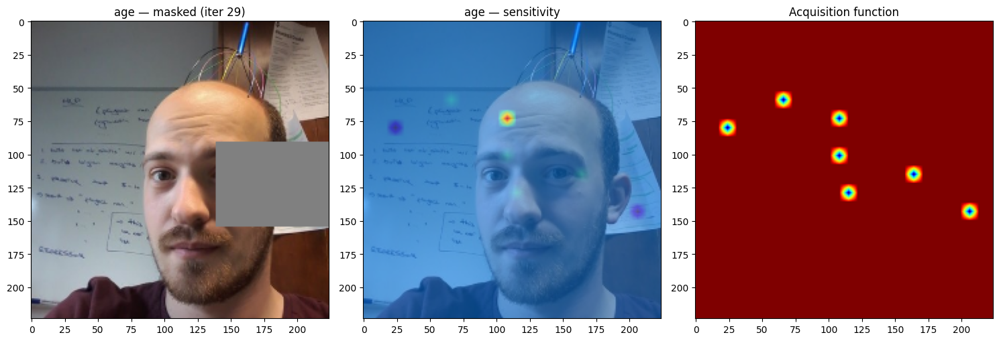

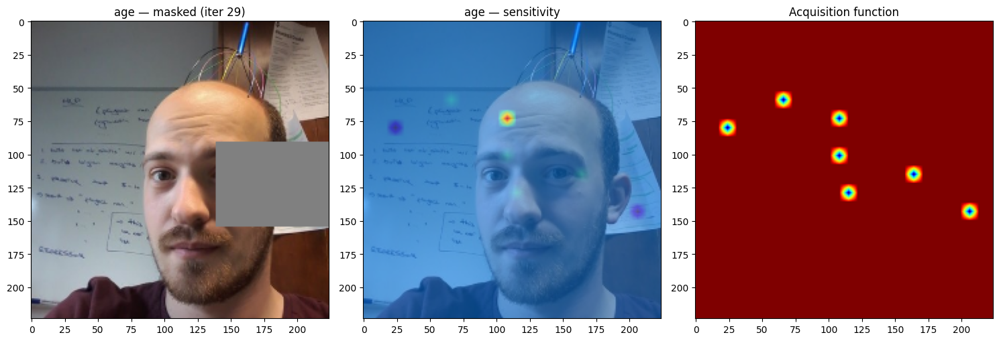


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[15.         14.          4.          4.        ]
 [16.         18.          4.          5.5       ]
 [13.18580895 22.69367838  4.41899058 13.87802105]
 [ 8.50764296  1.21160521 12.46433483 10.15808808]
 [15.         10.         10.         16.        ]
 [ 9.69369223 22.82941199  5.90594548 15.5339729 ]
 [13.078008    4.42096471 12.98854293 12.23004223]
 [23.         16.         11.5         4.        ]
 [ 1.45992693 23.15843058 14.09137704 16.        ]
 [21.87316685  4.3905101  10.78592176  7.67253842]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 17.666666666666668
mu mean/std: 1.9635873558537146e-05 0.008746110262968699
sig mean/std: 0.9999340220538152 0.007181644997967289
2025-10-15 10:15:39 | PID 615372 | RSS   579.0 MB | age                                                          len= 30 mean=17.666667 std=9.551033


In [75]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


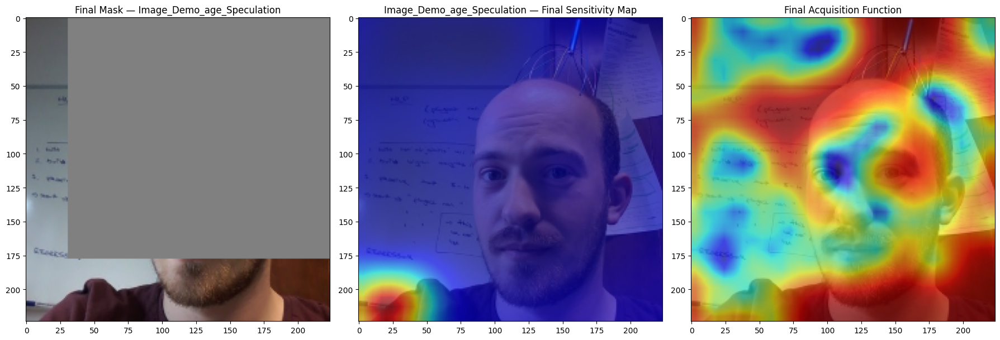

In [76]:
# === Final visualization after run_saliency_for_feature ===

feature_key = "Image_Demo_age_Speculation"  # change to your current feature
nx = len(np.unique(xv))
ny = len(np.unique(yv))
nw = len(np.unique(wv))
nh = len(np.unique(hv))

h_img, w_img = img.shape[:2]

# --- Recreate GP surface maps ---
try:
    ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))  # sensitivity (mu)
    sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))  # uncertainty (sig)
except Exception as ex:
    print("[ERROR] Could not reshape mu/sig:", ex)
    raise

# --- Resize for overlaying on image ---
ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)
acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

# --- Plot final outputs ---
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Mask overlay (optional last mask for reference)
x0, y0, ww, hh = [float(v) for v in np.ravel(Xm[-1])]
scale_x = w_img / grid_pos
scale_y = h_img / grid_pos
x1 = max(int(x0 * scale_x - ww * scale_x), 0)
y1 = max(int(y0 * scale_y - hh * scale_y), 0)
x2 = min(int(x0 * scale_x + ww * scale_x), w_img)
y2 = min(int(y0 * scale_y + hh * scale_y), h_img)
masked_img = img.copy()
masked_img[y1:y2, x1:x2, :] = 128

ax[0].imshow(masked_img)
ax[0].set_title(f"Final Mask — {feature_key}")

# Sensitivity (overlayed like the paper)
ax[1].imshow(img)
ax[1].imshow(ov_img, alpha=0.6, cmap="jet")
ax[1].set_title(f"{feature_key} — Final Sensitivity Map")

# Acquisition function
ax[2].imshow(img)
ax[2].imshow(acq_img, alpha=0.6, cmap="jet")
ax[2].set_title("Final Acquisition Function")

plt.tight_layout()
plt.show()


In [77]:
def run_saliency_for_feature(demo_feature, img, baseline_scores):
    """
    Run a full occlusion + GP saliency loop for one demographic feature.
    Includes standardization of target deltas, exploration control, and
    final debug metrics for speculation score behavior.
    """
    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")

    # Per-feature storage
    fm_dict = {feature_key: []}             # delta scores
    raw_scores = []                         # raw masked speculation scores
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]
    prev_state = None

    # Grid constants
    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])

    for i in range(50):  # more iterations for better GP coverage
        try:
            # --- Mask ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))
            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)
            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- Model call ---
            if SKIP_VLM:
                masked_score = np.random.rand() * 100
            else:
                _, _, masked_result = infer_image_demographics_with_retry(
                    image_source=tmp_path,
                    model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                    demo_features=[demo_feature],
                    prefix="Image_Demo",
                )
                masked_score = masked_result.get(feature_key)

            try:
                os.remove(tmp_path)
            except:
                pass

            # --- Delta computation ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None or masked_score is None:
                continue

            delta = masked_score - base_score
            fm_dict[feature_key].append(float(delta))
            raw_scores.append(float(masked_score))

            # --- Prepare GP data ---
            fm_mean = np.array(fm_dict[feature_key])
            Xm_arr = np.array(Xm)
            X_norm = X / max_vals
            Xm_norm = Xm_arr / max_vals

            # ✅ Standardize targets for GP
            fm_mean_std = (fm_mean - np.mean(fm_mean)) / (np.std(fm_mean) + 1e-8)

            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.1)
            gp.fit(Xm_norm, fm_mean_std)
            mu_raw, sig = gp.predict(X_norm, return_std=True)

            # Re-scale predictions to original delta scale
            mu = mu_raw * np.std(fm_mean) + np.mean(fm_mean)

            # --- Acquisition (balanced exploitation & exploration) ---
            acq = mu + 0.5 * sig + 0.05 * (X[:, 2] + X[:, 3])

            # Reward distant, under-sampled areas (exploration bias)
            if len(Xm) > 5:
                dist = np.min(np.linalg.norm(X[:, None, :] - np.array(Xm)[None, :, :], axis=-1), axis=1)
                acq += 0.05 * dist

            # --- Choose next state ---
            acq_std = np.std(acq)
            if acq_std < 1e-3:
                aq_bin = np.random.randint(len(X))
            else:
                aq_bin = int(np.argmax(acq))

            prev_state = state.copy()
            state = X[aq_bin].astype(float)

            # --- Exploration triggers ---
            if np.allclose(state, prev_state) or sig.std() < 0.05:
                jitter = np.random.randn(4) * [1.0, 1.0, 2.0, 2.0]
                state += jitter
                state = np.clip(
                    state,
                    [X[:, 0].min(), X[:, 1].min(), X[:, 2].min(), X[:, 3].min()],
                    [X[:, 0].max(), X[:, 1].max(), X[:, 2].max(), X[:, 3].max()],
                )
                L(f"[DEBUG] Forced exploration jitter Δ={np.round(jitter, 2)}")

            if i % 8 == 0 and i > 0:
                L("[DEBUG] Periodic random exploration injected")
                state = X[np.random.randint(0, X.shape[0]), :].astype(float)

            Xm.append(state)

            # --- Visualization ---
            if i % 2 == 0:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- Final summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())
    print("masked speculation mean/std:", np.mean(raw_scores), np.std(raw_scores))

    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


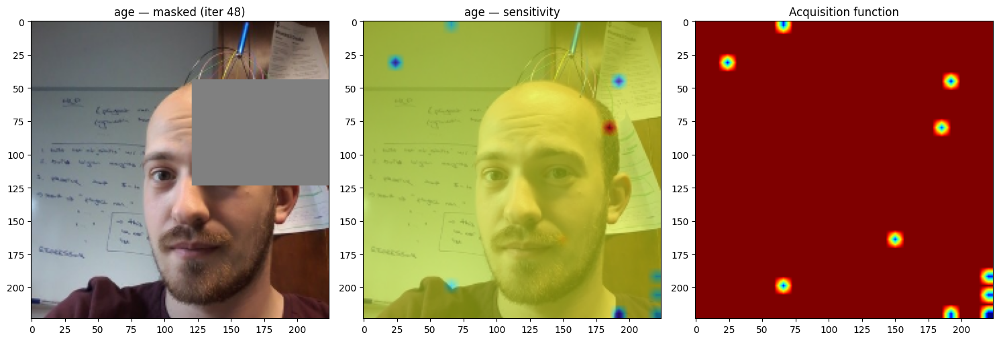

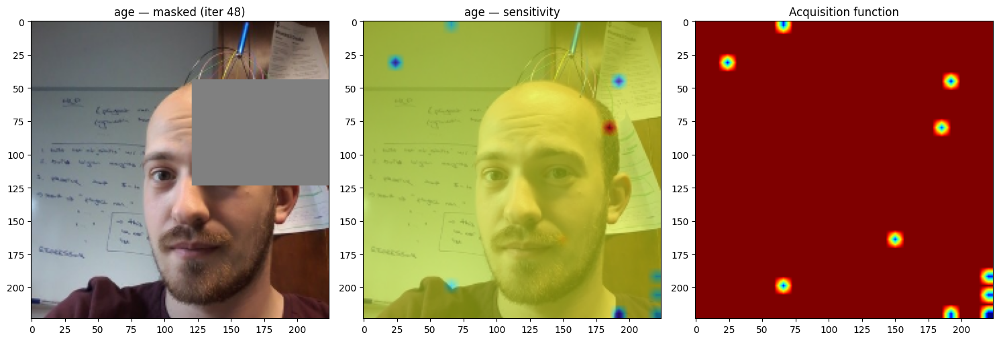

[DEBUG] Found 6 sections to parse
Image demographic parsing succeeded


/home/roberto-cerina/cam-env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


2025-10-15 11:19:06 | PID 615372 | RSS   562.4 MB | [DEBUG] Forced exploration jitter Δ=[-0.13 -0.11 -0.63  0.78]

--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[ 3.          4.          8.5         4.        ]
 [31.         31.         16.         16.        ]
 [30.04787354 31.         14.63591478 16.        ]
 [31.         31.         16.         16.        ]
 [29.54904802 31.         16.         13.14363371]
 [31.         31.         16.         16.        ]
 [31.         27.         16.         16.        ]
 [31.         29.         16.         16.        ]
 [27.         31.         16.         16.        ]
 [ 9.         28.          4.         16.        ]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 50  mean: 18.4
mu mean/std: 18.398981328745343 0.12568737575663566
sig mean/std: 0.9999058969756439 0.008180880500634043
masked speculation mean/std: 48.4 11.200000000000001
2025-10-15 11:19:06 | PID 615372 | RSS   562.4 MB | age                               

In [78]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)


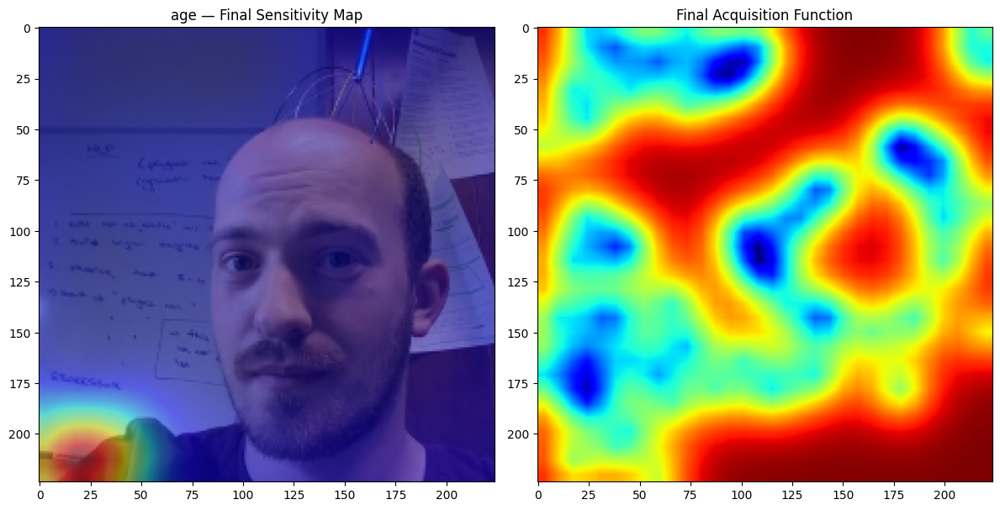

In [80]:
def plot_final_gp_summary(mu, sig, nx, ny, nw, nh, img, w_img, h_img, feature_name):
    ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
    sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
    ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)
    acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img)
    ax[0].imshow(ov_img, alpha=0.5, cmap="jet")
    ax[0].set_title(f"{feature_name} — Final Sensitivity Map")
    ax[1].imshow(acq_img, cmap="jet")
    ax[1].set_title("Final Acquisition Function")
    plt.tight_layout()
    plt.show()
plot_final_gp_summary(mu, sig, nx, ny, nw, nh, img, img.shape[1], img.shape[0], "age")


In [81]:
def run_saliency_for_feature(demo_feature, img, baseline_scores):
    """
    Run a full occlusion+GP saliency loop for one demographic feature.
    Uses smoothed multi-sample masking and amplified delta transformation
    to emphasize meaningful changes (e.g. ±10 speculation difference).
    """

    feature_name = demo_feature["title"].replace(" ", "_")
    feature_key = f"Image_Demo_{feature_name}_Speculation"

    L(f"\n=== Starting per-feature saliency loop for {feature_name} ===")

    fm_dict = {feature_key: []}
    raw_scores = []  # store masked speculation scores
    state = X[np.random.randint(0, X.shape[0]), :].astype(float)
    Xm = [state]
    prev_state = None

    nx, ny, nw, nh = len(np.unique(xv)), len(np.unique(yv)), len(np.unique(wv)), len(np.unique(hv))
    h_img, w_img = img.shape[:2]
    scale_x = w_img / grid_pos
    scale_y = h_img / grid_pos
    max_vals = np.array([xv.max(), yv.max(), wv.max(), hv.max()])

    for i in range(30):
        try:
            # --- 1. Apply occlusion mask ---
            x0, y0, ww, hh = [float(v) for v in np.ravel(state)]
            x0_px = int(round(x0 * scale_x))
            y0_px = int(round(y0 * scale_y))
            ww_px = int(round(ww * scale_x))
            hh_px = int(round(hh * scale_y))
            x1 = max(x0_px - ww_px, 0)
            y1 = max(y0_px - hh_px, 0)
            x2 = min(x0_px + ww_px, w_img)
            y2 = min(y0_px + hh_px, h_img)

            masked_img = img.copy()
            masked_img[y1:y2, x1:x2, :] = 128

            tmp_fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
            os.close(tmp_fd)
            cv2.imwrite(tmp_path, cv2.cvtColor(masked_img, cv2.COLOR_RGB2BGR))

            # --- 2. Query VLM multiple times for stability ---
            n_repeat = 2
            masked_scores = []
            for _ in range(n_repeat):
                if SKIP_VLM:
                    masked_scores.append(np.random.rand() * 100)  # simulate API scale (0–100)
                else:
                    _, _, masked_result = infer_image_demographics_with_retry(
                        image_source=tmp_path,
                        model_name="Llama-4-Maverick-17B-128E-Instruct-FP8",
                        demo_features=[demo_feature],
                        prefix="Image_Demo",
                    )
                    ms = masked_result.get(feature_key)
                    if ms is not None:
                        masked_scores.append(float(ms))

            try:
                os.remove(tmp_path)
            except:
                pass

            if len(masked_scores) == 0:
                continue

            masked_score = np.mean(masked_scores)  # averaged speculation score
            raw_scores.append(masked_score)

            # --- 3. Compute amplified delta ---
            base_score = baseline_scores.get(feature_key)
            if base_score is None:
                continue

            delta_raw = masked_score - base_score
            p = 1.6   # power transform exponent
            K = 6.0   # global amplification
            delta_trans = np.sign(delta_raw) * (abs(delta_raw) ** p)
            delta_trans = (delta_trans / (abs(base_score) + 1e-6)) * K

            fm_dict[feature_key].append(float(delta_trans))

            # --- 4. Prepare GP data ---
            fm_mean = np.array(fm_dict[feature_key])
            # Standardize target for GP stability
            fm_mean = (fm_mean - fm_mean.mean()) / (fm_mean.std() + 1e-6)

            Xm_arr = np.array(Xm)
            X_norm = X / max_vals
            Xm_norm = Xm_arr / max_vals

            # --- 5. Fit GP ---
            gp = GaussianProcessRegressor(kernel=Matern(nu=1.5), alpha=0.05)
            gp.fit(Xm_norm, fm_mean)
            mu, sig = gp.predict(X_norm, return_std=True)

            # --- 6. Acquisition with exploration bias ---
            acq = mu + 2.5 * sig + 0.05 * (X[:, 2] + X[:, 3])  # stronger sig weight

            # Add spatial exploration encouragement
            if len(Xm) > 5:
                dist = np.min(np.linalg.norm(X[:, None, :] - np.array(Xm)[None, :, :], axis=-1), axis=1)
                acq += 0.1 * dist

            acq_std = np.std(acq)
            if acq_std < 1e-3:
                aq_bin = np.random.randint(len(X))
            else:
                aq_bin = int(np.argmax(acq))

            # --- 7. Update next state ---
            prev_state = state.copy()
            state = X[aq_bin].astype(float)

            # Inject random jitter if stagnant
            if np.allclose(state, prev_state) or sig.std() < 0.05:
                jitter = np.random.randn(4) * [1.5, 1.5, 2.0, 2.0]
                state += jitter
                state = np.clip(
                    state,
                    [X[:, 0].min(), X[:, 1].min(), X[:, 2].min(), X[:, 3].min()],
                    [X[:, 0].max(), X[:, 1].max(), X[:, 2].max(), X[:, 3].max()],
                )
                L(f"[DEBUG] Forced exploration jitter Δ={np.round(jitter, 2)}")

            if i % 6 == 0 and i > 0:
                rand_state = X[np.random.randint(0, X.shape[0]), :].astype(float)
                L("[DEBUG] Periodic random exploration injected")
                state = rand_state

            Xm.append(state)

            # --- 8. Visualization ---
            if i % 1 == 0:
                ov = mu.reshape(nx, ny, nw, nh).mean(axis=(-1, -2))
                sxy = np.sum(sig.reshape(nx, ny, nw, nh), axis=(-1, -2))
                ov_img = cv2.resize(ov.T.astype(np.float32), (w_img, h_img), interpolation=cv2.INTER_LINEAR)

                fig, ax = plt.subplots(1, 3, figsize=(15, 5))
                ax[0].imshow(masked_img)
                ax[0].set_title(f"{feature_name} — masked (iter {i})")

                ax[1].imshow(img)
                ax[1].imshow(ov_img, alpha=0.5, cmap="jet")
                ax[1].set_title(f"{feature_name} — sensitivity")

                acq_img = cv2.resize((5 * sxy.T + ov.T).astype(np.float32), (w_img, h_img))
                ax[2].imshow(acq_img, cmap="jet")
                ax[2].set_title("Acquisition function")

                plt.tight_layout()
                display.clear_output(wait=True)
                display.display(plt.gcf())
                plt.pause(0.1)
                plt.close(fig)

        except Exception as e:
            L(f"{feature_name} ITER {i} exception:\n{traceback.format_exc()}")
            break

    # --- 9. Final debug summary ---
    print("\n--- FINAL DEBUG SUMMARY ---")
    print("Xm sample ranges (first 10):\n", np.array(Xm[:10]))
    print("fm_dict lengths per feature:")
    for k, v in fm_dict.items():
        print(k, len(v), " mean:", np.mean(v))
    print("mu mean/std:", mu.mean(), mu.std())
    print("sig mean/std:", sig.mean(), sig.std())
    print("masked speculation mean/std:", np.mean(raw_scores), np.std(raw_scores))

    arr = np.array(fm_dict[feature_key])
    L(f"{feature_name:60s} len={len(arr):3d} mean={arr.mean():.6f} std={arr.std():.6f}")


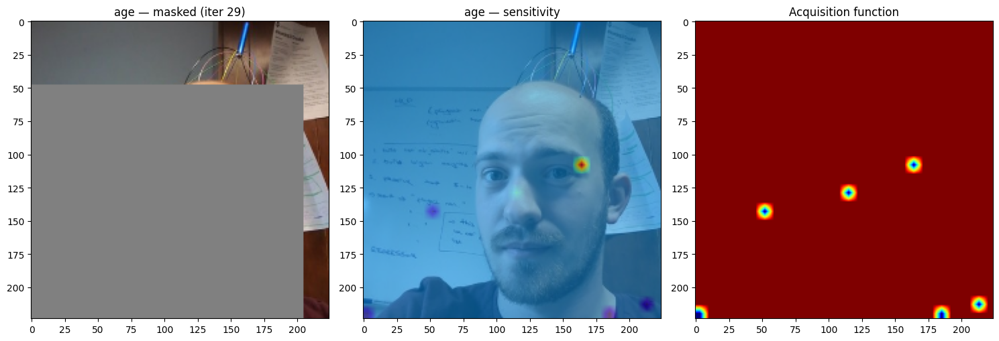

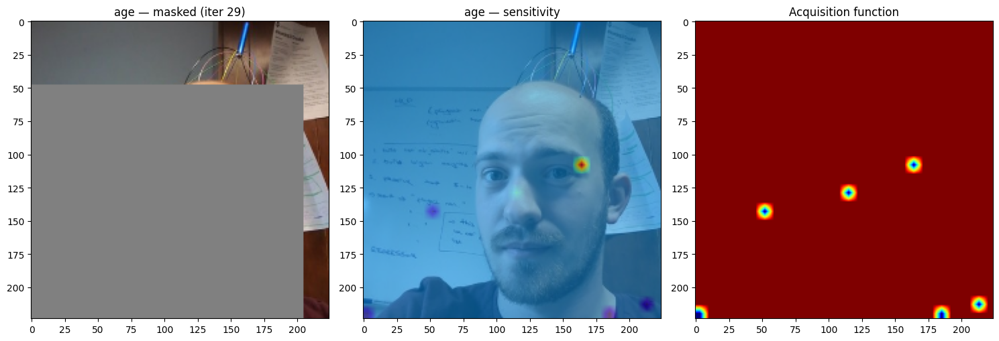


--- FINAL DEBUG SUMMARY ---
Xm sample ranges (first 10):
 [[23.         15.         14.5        16.        ]
 [ 0.         31.         16.         16.        ]
 [26.42097817 12.57540008 16.         16.        ]
 [ 0.40550122  1.68924683 13.17197743 15.21440472]
 [ 1.57783062  0.22725083 16.         16.        ]
 [ 1.01615076  0.         16.         16.        ]
 [30.06854499 29.58689511 15.25808217 16.        ]
 [30.         30.          8.5         7.        ]
 [ 7.4773005  16.66556933 16.         14.2508126 ]
 [18.81406764  0.         16.         15.05381551]]
fm_dict lengths per feature:
Image_Demo_age_Speculation 30  mean: 36.0790367472448
mu mean/std: -6.085490818837128e-06 0.008334061049163016
sig mean/std: 0.9999434474746987 0.006648951372536045
masked speculation mean/std: 52.5 16.26601774661928
2025-10-15 11:35:14 | PID 615372 | RSS   597.9 MB | age                                                          len= 30 mean=36.079037 std=41.500239


In [82]:
# Pick one feature to test
test_feature = [d for d in demo_features if "age" in d["title"].lower()][0]

# Run the saliency loop for that single feature
run_saliency_for_feature(test_feature, img, baseline_scores)
